# 実験結果の可視化

`outputs/` 以下の `metrics.json` と `meta.json` を再帰的に走査し，手法ごとの精度（seed 間の平均と標準偏差），処理速度，混同行列，実際の画像による予測例を可視化する．
図は各実験のディレクトリ（例: `outputs/ex001_odai_image_type/figures/`）に保存する．
下の設定のセルで，可視化する実験・手法・設定を変数で選択できる．

In [1]:
import glob
import json
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib import font_manager
from PIL import Image

# ===== 設定 =====
PROJECT_DIR = os.path.abspath(".")
OUTPUT_ROOT = os.path.join(PROJECT_DIR, "outputs")
EXPERIMENTS = ["ex001_odai_image_type"]          # 可視化する実験（複数指定可）
METHODS = None                                  # None で全手法．例: ["vlm_Qwen3-VL-8B-Instruct", "probe_hand_siglip2-so400m-patch14-384"]
SELECT_METRIC = "flat_macro_f1"                 # 手法ごとに最良の設定を選ぶ指標
EXAMPLE_METHODS = {                             # 予測例の図に表示する手法と設定（表示名: (手法, 設定)）
    "SigLIP2+probe(hand)": ("probe_hand_siglip2-so400m-patch14-384", None),
    "SigLIP2+probe(VLM)": ("probe_vlm_siglip2-so400m-patch14-384", None),
    "Qwen3-VL-8B": ("vlm_Qwen3-VL-8B-Instruct", "v2_px200704"),
}
CONFUSION_METHODS = None                        # None で各系統の最良の手法．手法名のリストでも指定できる
IMAGE_DIR = "/mnt/d/Bokete_Scraping_v3.2/datasets/images"
FLAT_LABELS = ["photo", "anime", "manga", "text", "anaume", "karuta", "illust"]
FORMAT_LABELS = ["normal", "text", "anaume", "karuta"]
DOMAIN_LABELS = ["photo", "anime", "manga", "illust"]

for f in ["/usr/share/fonts/opentype/ipaexfont-gothic/ipaexg.ttf"]:
    if os.path.exists(f):
        font_manager.fontManager.addfont(f)
        plt.rcParams["font.family"] = font_manager.FontProperties(fname=f).get_name()
plt.rcParams["figure.dpi"] = 110

## 結果の読み込み

In [2]:
def load_runs(experiments: list) -> pd.DataFrame:
    """outputs/{実験}/{手法}/{設定}/{seed}/ の metrics.json と meta.json を読み込み，1行1実行の表にする．

    Args:
        experiments (list[str]): 実験のディレクトリ名のリスト．

    Returns:
        pd.DataFrame: 列 experiment, method, setting, seed，評価の指標，学習用データの指標，処理速度を持つ表．
    """
    rows = []
    for ex in experiments:
        for path in glob.glob(os.path.join(OUTPUT_ROOT, ex, "*", "*", "*", "metrics.json")):
            seed_dir = os.path.dirname(path)
            setting_dir = os.path.dirname(seed_dir)
            method_dir = os.path.dirname(setting_dir)
            metrics = json.load(open(path))
            meta = json.load(open(os.path.join(seed_dir, "meta.json")))
            row = {"experiment": ex, "method": os.path.basename(method_dir), "setting": os.path.basename(setting_dir),
                   "seed": int(os.path.basename(seed_dir)), "run_dir": seed_dir}
            row.update({k: v for k, v in metrics["eval"].items() if k != "per_class"})
            row.update({f"f1_{c}": metrics["eval"]["per_class"][c]["f1-score"] for c in FLAT_LABELS})
            row.update({f"recall_{c}": metrics["eval"]["per_class"][c]["recall"] for c in FLAT_LABELS})
            row.update({f"precision_{c}": metrics["eval"]["per_class"][c]["precision"] for c in FLAT_LABELS})
            row.update({f"train_{k}": v for k, v in metrics.get("train", {}).items()})
            row["images_per_sec"] = meta.get("throughput", {}).get("images_per_sec_infer")
            rows.append(row)
    df = pd.DataFrame(rows)
    return df if METHODS is None else df[df["method"].isin(METHODS)]


def load_benchmark(experiment: str) -> dict:
    """benchmark.py で測定した埋め込みモデルの処理速度を読み込む．

    Args:
        experiment (str): 実験のディレクトリ名．

    Returns:
        dict[str, float]: モデルの短い名前をキー，1秒あたりの画像数を値とする辞書．
    """
    out = {}
    for path in glob.glob(os.path.join(OUTPUT_ROOT, experiment, "benchmark", "*", "*", "*", "meta.json")):
        m = json.load(open(path))
        out[m["model"].split("/")[-1]] = max(out.get(m["model"].split("/")[-1], 0), m["images_per_sec"])
    return out


runs = load_runs(EXPERIMENTS)
metric_cols = ["flat_accuracy", "flat_macro_f1", "format_accuracy", "format_macro_f1", "domain_accuracy",
               "domain_macro_f1"] + [f"f1_{c}" for c in FLAT_LABELS] + [f"recall_{c}" for c in FLAT_LABELS] + \
              [f"precision_{c}" for c in FLAT_LABELS]
agg = runs.groupby(["experiment", "method", "setting"])[metric_cols + ["images_per_sec"]].agg(["mean", "std"])
agg.columns = [f"{a}_{b}" for a, b in agg.columns]
agg = agg.reset_index()
agg["n_seeds"] = runs.groupby(["experiment", "method", "setting"]).size().values
# 比較の単位（group）: 手法名と，正則化の強さ C を除いた設定の組．C は group の中で最良の値を選ぶ
setting_wo_c = agg["setting"].str.replace(r"_?C[0-9.]+$", "", regex=True).replace({"default": ""})
agg["group"] = agg["method"] + np.where(setting_wo_c != "", " [" + setting_wo_c + "]", "")

MODEL_SHORT = {"clip-vit-base-patch32": "CLIP-B/32", "siglip2-base-patch16-224": "SigLIP2-B",
               "siglip2-so400m-patch14-384": "SigLIP2-so400m"}
FAMILY_COLORS = {"zeroshot": "#9e9e9e", "probe_weak": "#ff9800", "probe_hand": "#4caf50", "probe_vlm": "#1f77b4",
                 "vlm": "#d62728", "ocr": "#9c27b0"}


def family_of(method: str) -> str:
    """手法名から系統（zeroshot, probe_weak, probe_hand, probe_vlm, vlm, ocr）を求める．

    Args:
        method (str): 手法のディレクトリ名．

    Returns:
        str: 系統の名前．
    """
    return next(f for f in ["probe_weak", "probe_hand", "probe_vlm", "zeroshot", "vlm", "ocr"] if method.startswith(f))


def short_label(method: str, setting: str) -> str:
    """図に表示する短い手法名を作る．

    Args:
        method (str): 手法のディレクトリ名．
        setting (str): 設定のディレクトリ名．

    Returns:
        str: 例 "SigLIP2-so400m + probe(VLM-8B)"，"Qwen3-VL-8B (v2, 448px)"．
    """
    fam = family_of(method)
    if fam == "vlm":
        size = method.split("-")[2]
        prompt, px = setting.split("_px")
        return f"Qwen3-VL-{size} ({prompt}, {int(int(px) ** 0.5)}px)"
    if fam == "ocr":
        return "YomiToku OCR rule"
    model = MODEL_SHORT.get(method.split("_")[-1], method.split("_")[-1])
    if fam == "zeroshot":
        return f"{model} zero-shot"
    if fam == "probe_vlm":
        return f"{model} + probe(VLM-{setting.split('-')[2]})"
    return f"{model} + probe({'meta' if fam == 'probe_weak' else 'hand'})"


agg["family"] = agg["method"].map(family_of)
agg["label"] = [short_label(m, s) for m, s in zip(agg["method"], agg["setting"])]
pd.set_option("display.width", 250)
agg[["method", "setting", "n_seeds", "flat_accuracy_mean", "flat_accuracy_std", "flat_macro_f1_mean",
     "format_accuracy_mean", "domain_accuracy_mean"]].sort_values("flat_macro_f1_mean", ascending=False)

,method,setting,n_seeds,flat_accuracy_mean,flat_accuracy_std,flat_macro_f1_mean,format_accuracy_mean,domain_accuracy_mean
28,probe_vlm_siglip2-so400m-patch14-384,Qwen3-VL-8B-Instruct_v2_px200704_C0.01,3,0.912879,0.008604,0.892916,0.934091,0.925758
46,vlm_Qwen3-VL-8B-Instruct,v2_px200704,1,0.904545,NaN,0.886506,0.922727,0.938636
25,probe_vlm_siglip2-so400m-patch14-384,Qwen3-VL-4B-Instruct_v2_px200704_C0.01,3,0.903030,0.009185,0.886448,0.921212,0.931818
26,probe_vlm_siglip2-so400m-patch14-384,Qwen3-VL-4B-Instruct_v2_px200704_C0.1,3,0.887879,0.002624,0.872125,0.908333,0.927273
43,vlm_Qwen3-VL-4B-Instruct,v2_px200704,1,0.884091,NaN,0.869532,0.902273,0.925000
29,probe_vlm_siglip2-so400m-patch14-384,Qwen3-VL-8B-Instruct_v2_px200704_C0.1,3,0.887121,0.011439,0.864631,0.913636,0.915152
47,vlm_Qwen3-VL-8B-Instruct,v2_px65536,1,0.879545,NaN,0.862099,0.895455,0.927273
9,probe_hand_siglip2-so400m-patch14-384,C1.0,3,0.881818,0.002273,0.854162,0.913636,0.934848
7,probe_hand_siglip2-so400m-patch14-384,C0.01,3,0.884091,0.003936,0.850593,0.921212,0.931061
27,probe_vlm_siglip2-so400m-patch14-384,Qwen3-VL-4B-Instruct_v2_px200704_C1.0,3,0.861364,0.009091,0.846978,0.884848,0.918939


## 手法ごとの最良の設定

In [3]:
best = agg.loc[agg.groupby(["experiment", "group"])[f"{SELECT_METRIC}_mean"].idxmax()].copy()
best = best.sort_values("flat_macro_f1_mean", ascending=False).reset_index(drop=True)
for ex in EXPERIMENTS:
    bench = load_benchmark(ex)
    for i, r in best.iterrows():
        model = r["method"].split("_")[-1]
        if r["method"].startswith(("zeroshot", "probe")) and model in bench:
            best.loc[i, "images_per_sec_bench"] = bench[model]
best["images_per_sec_best"] = best.get("images_per_sec_bench", pd.Series(dtype=float)).fillna(best["images_per_sec_mean"])
best["hours_all"] = 6_823_270 / best["images_per_sec_best"] / 3600
summary_cols = ["label", "group", "method", "setting", "n_seeds", "flat_accuracy_mean", "flat_accuracy_std", "flat_macro_f1_mean",
                "flat_macro_f1_std", "format_accuracy_mean", "domain_accuracy_mean", "images_per_sec_best", "hours_all"]
for ex in EXPERIMENTS:
    fig_dir = os.path.join(OUTPUT_ROOT, ex, "figures")
    os.makedirs(fig_dir, exist_ok=True)
    best[best["experiment"] == ex][summary_cols].to_csv(os.path.join(fig_dir, "summary_best.csv"), index=False)
    agg[agg["experiment"] == ex].to_csv(os.path.join(fig_dir, "summary_all.csv"), index=False)
best[summary_cols].round(3)

,label,group,method,setting,n_seeds,flat_accuracy_mean,flat_accuracy_std,flat_macro_f1_mean,flat_macro_f1_std,format_accuracy_mean,domain_accuracy_mean,images_per_sec_best,hours_all
0,SigLIP2-so400m + probe(VLM-8B),probe_vlm_siglip2-so400m-patch14-384 [Qwen3-VL...,probe_vlm_siglip2-so400m-patch14-384,Qwen3-VL-8B-Instruct_v2_px200704_C0.01,3,0.913,0.009,0.893,0.010,0.934,0.926,177.503,10.678
1,"Qwen3-VL-8B (v2, 448px)",vlm_Qwen3-VL-8B-Instruct [v2_px200704],vlm_Qwen3-VL-8B-Instruct,v2_px200704,1,0.905,NaN,0.887,NaN,0.923,0.939,27.234,69.595
2,SigLIP2-so400m + probe(VLM-4B),probe_vlm_siglip2-so400m-patch14-384 [Qwen3-VL...,probe_vlm_siglip2-so400m-patch14-384,Qwen3-VL-4B-Instruct_v2_px200704_C0.01,3,0.903,0.009,0.886,0.008,0.921,0.932,177.503,10.678
3,"Qwen3-VL-4B (v2, 448px)",vlm_Qwen3-VL-4B-Instruct [v2_px200704],vlm_Qwen3-VL-4B-Instruct,v2_px200704,1,0.884,NaN,0.870,NaN,0.902,0.925,45.476,41.678
4,"Qwen3-VL-8B (v2, 256px)",vlm_Qwen3-VL-8B-Instruct [v2_px65536],vlm_Qwen3-VL-8B-Instruct,v2_px65536,1,0.880,NaN,0.862,NaN,0.895,0.927,38.728,48.940
5,SigLIP2-so400m + probe(hand),probe_hand_siglip2-so400m-patch14-384,probe_hand_siglip2-so400m-patch14-384,C1.0,3,0.882,0.002,0.854,0.003,0.914,0.935,177.503,10.678
6,"Qwen3-VL-4B (v2, 256px)",vlm_Qwen3-VL-4B-Instruct [v2_px65536],vlm_Qwen3-VL-4B-Instruct,v2_px65536,1,0.855,NaN,0.837,NaN,0.877,0.918,64.262,29.494
7,SigLIP2-B + probe(VLM-8B),probe_vlm_siglip2-base-patch16-224 [Qwen3-VL-8...,probe_vlm_siglip2-base-patch16-224,Qwen3-VL-8B-Instruct_v2_px200704_C0.01,3,0.855,0.004,0.825,0.005,0.878,0.920,881.516,2.150
8,CLIP-B/32 + probe(VLM-8B),probe_vlm_clip-vit-base-patch32 [Qwen3-VL-8B-I...,probe_vlm_clip-vit-base-patch32,Qwen3-VL-8B-Instruct_v2_px200704_C0.01,3,0.814,0.005,0.791,0.006,0.832,0.926,1087.381,1.743
9,SigLIP2-B + probe(hand),probe_hand_siglip2-base-patch16-224,probe_hand_siglip2-base-patch16-224,C0.1,3,0.820,0.013,0.791,0.014,0.849,0.927,881.516,2.150


## 無作為抽出の画像（random プール，240件）のみでの精度

評価用データは希少なクラスを多めに抽出しているため，全お題の分布に近い random プールのみでも正解率を求める（seed 間の平均）．

In [4]:
def pool_accuracy(df_best: pd.DataFrame, pool: str = "random") -> pd.DataFrame:
    """指定したプールの画像のみで，各手法の最良の設定の7クラス・形式・画風の正解率を求める．

    Args:
        df_best (pd.DataFrame): best の表．
        pool (str): プール名．

    Returns:
        pd.DataFrame: 列 method, setting, n, flat_accuracy, format_accuracy, domain_accuracy を持つ表（seed 間の平均）．
    """
    rows = []
    for _, r in df_best.iterrows():
        dirs = runs[(runs["method"] == r["method"]) & (runs["setting"] == r["setting"])]["run_dir"]
        accs = []
        for d in dirs:
            p = pd.read_csv(os.path.join(d, "predictions.csv"))
            p = p[p["pool"] == pool]
            dm = p["pred_domain"].notna()
            accs.append(((p["pred_flat"] == p["true_flat"]).mean(), (p["pred_format"] == p["true_format"]).mean(),
                         (p.loc[dm, "pred_domain"] == p.loc[dm, "true_domain"]).mean() if dm.any() else np.nan, len(p)))
        a = np.array(accs, dtype=float)
        rows.append({"label": r["label"], "group": r["group"], "setting": r["setting"], "n": int(a[0, 3]), "flat_accuracy": a[:, 0].mean(),
                     "format_accuracy": a[:, 1].mean(), "domain_accuracy": a[:, 2].mean()})
    return pd.DataFrame(rows).sort_values("flat_accuracy", ascending=False)


for ex in EXPERIMENTS:
    random_acc = pool_accuracy(best[best["experiment"] == ex])
    random_acc.to_csv(os.path.join(OUTPUT_ROOT, ex, "figures", "summary_random_pool.csv"), index=False)
random_acc.round(3)

,label,group,setting,n,flat_accuracy,format_accuracy,domain_accuracy
0,SigLIP2-so400m + probe(VLM-8B),probe_vlm_siglip2-so400m-patch14-384 [Qwen3-VL...,Qwen3-VL-8B-Instruct_v2_px200704_C0.01,240,0.938,0.960,0.932
2,SigLIP2-so400m + probe(VLM-4B),probe_vlm_siglip2-so400m-patch14-384 [Qwen3-VL...,Qwen3-VL-4B-Instruct_v2_px200704_C0.01,240,0.926,0.947,0.918
1,"Qwen3-VL-8B (v2, 448px)",vlm_Qwen3-VL-8B-Instruct [v2_px200704],v2_px200704,240,0.917,0.938,0.942
5,SigLIP2-so400m + probe(hand),probe_hand_siglip2-so400m-patch14-384,C1.0,240,0.903,0.949,0.921
3,"Qwen3-VL-4B (v2, 448px)",vlm_Qwen3-VL-4B-Instruct [v2_px200704],v2_px200704,240,0.900,0.921,0.921
4,"Qwen3-VL-8B (v2, 256px)",vlm_Qwen3-VL-8B-Instruct [v2_px65536],v2_px65536,240,0.879,0.892,0.929
6,"Qwen3-VL-4B (v2, 256px)",vlm_Qwen3-VL-4B-Instruct [v2_px65536],v2_px65536,240,0.879,0.904,0.917
7,SigLIP2-B + probe(VLM-8B),probe_vlm_siglip2-base-patch16-224 [Qwen3-VL-8...,Qwen3-VL-8B-Instruct_v2_px200704_C0.01,240,0.869,0.899,0.922
10,CLIP-B/32 + probe(hand),probe_hand_clip-vit-base-patch32,C0.01,240,0.849,0.881,0.921
9,SigLIP2-B + probe(hand),probe_hand_siglip2-base-patch16-224,C0.1,240,0.840,0.881,0.908


## 正解率とマクロ F1（seed 間の平均 ± 標準偏差）

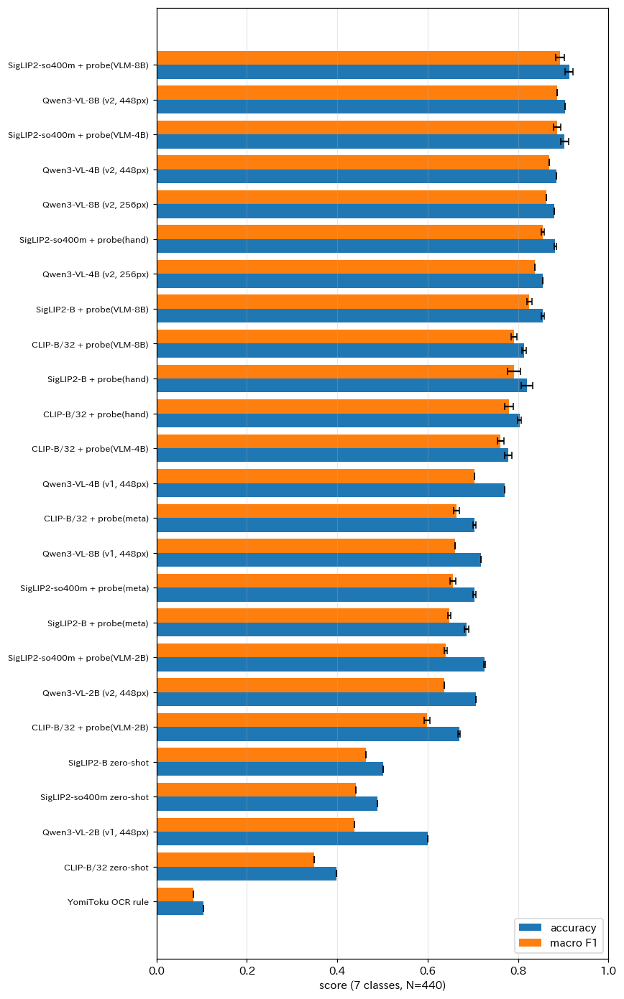

In [5]:
def plot_accuracy(df: pd.DataFrame, path: str) -> None:
    """手法ごとの7クラスの正解率とマクロ F1 を横棒グラフで描く．

    Args:
        df (pd.DataFrame): best の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    df = df.sort_values("flat_macro_f1_mean")
    y = np.arange(len(df))
    fig, ax = plt.subplots(figsize=(8, 0.45 * len(df) + 1.5))
    ax.barh(y - 0.2, df["flat_accuracy_mean"], 0.4, xerr=df["flat_accuracy_std"].fillna(0), label="accuracy", capsize=3)
    ax.barh(y + 0.2, df["flat_macro_f1_mean"], 0.4, xerr=df["flat_macro_f1_std"].fillna(0), label="macro F1", capsize=3)
    ax.set_yticks(y, df["label"], fontsize=8)
    ax.set_xlim(0, 1)
    ax.set_xlabel("score (7 classes, N=440)")
    ax.legend(loc="lower right")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


for ex in EXPERIMENTS:
    plot_accuracy(best[best["experiment"] == ex], os.path.join(OUTPUT_ROOT, ex, "figures", "fig_accuracy.png"))

## クラスごとの F1

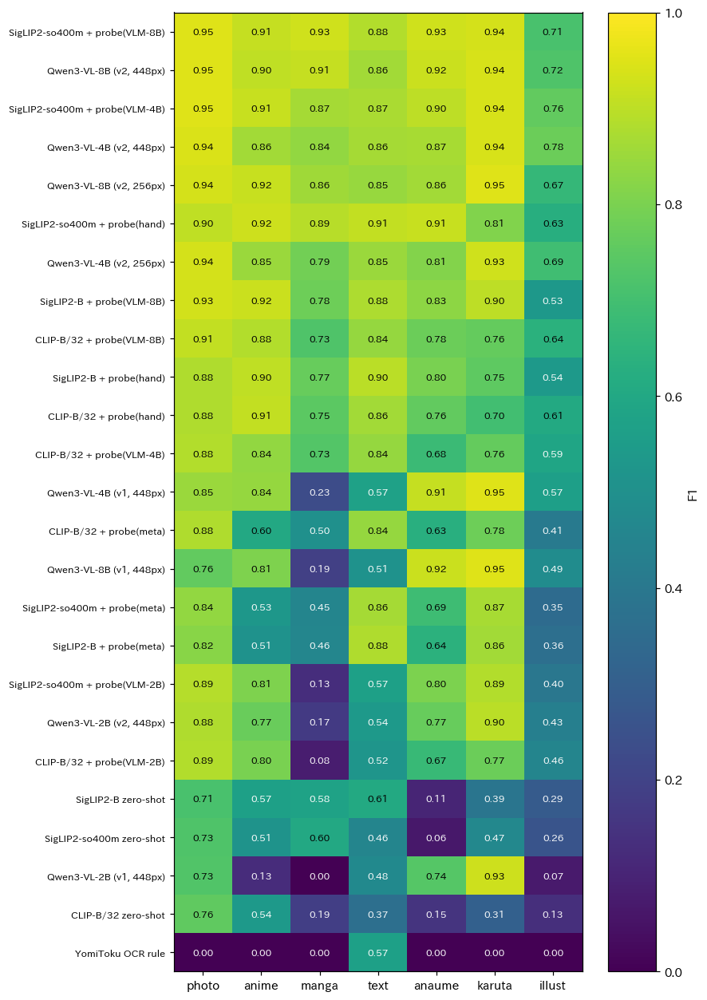

In [6]:
def plot_per_class(df: pd.DataFrame, path: str) -> None:
    """手法とクラスの F1 をヒートマップで描く．

    Args:
        df (pd.DataFrame): best の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    mat = df[[f"f1_{c}_mean" for c in FLAT_LABELS]].values
    fig, ax = plt.subplots(figsize=(8, 0.4 * len(df) + 1.5))
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(FLAT_LABELS)), FLAT_LABELS)
    ax.set_yticks(range(len(df)), df["label"], fontsize=8)
    for i, j in np.ndindex(mat.shape):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", color="white" if mat[i, j] < 0.6 else "black", fontsize=8)
    fig.colorbar(im, ax=ax, label="F1")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


for ex in EXPERIMENTS:
    plot_per_class(best[best["experiment"] == ex], os.path.join(OUTPUT_ROOT, ex, "figures", "fig_per_class_f1.png"))

## 処理速度と精度の関係

横軸は1秒あたりの処理枚数（対数軸），縦軸は7クラスのマクロ F1 である．埋め込みモデルの速度は `benchmark.py` の実測値（DataLoader で前処理を並列化），VLM の速度は vLLM での実測値である．

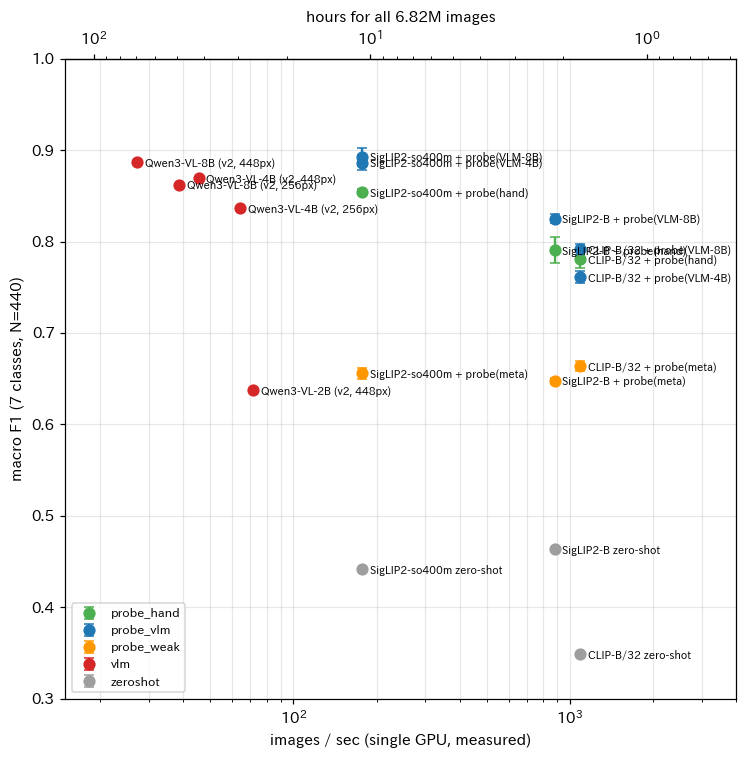

In [7]:
def plot_speed(df: pd.DataFrame, path: str) -> None:
    """処理速度とマクロ F1 の散布図を描く．上側の軸に全画像の処理に要する時間を示す．

    見やすさのため，VLM のプロンプト v1 と，蒸留の教師が 2B の条件は除く．

    Args:
        df (pd.DataFrame): best の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    df = df[~df["setting"].str.startswith("v1_") & ~df["setting"].str.contains("2B-Instruct") & (df["family"] != "ocr")]
    fig, ax = plt.subplots(figsize=(7, 7))
    for fam, d in df.groupby("family"):
        ax.errorbar(d["images_per_sec_best"], d["flat_macro_f1_mean"], yerr=d["flat_macro_f1_std"].fillna(0), fmt="o",
                    capsize=3, color=FAMILY_COLORS[fam], label=fam, markersize=7)
    for _, r in df.iterrows():
        ax.annotate(r["label"], (r["images_per_sec_best"], r["flat_macro_f1_mean"]), fontsize=7,
                    xytext=(5, -3), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlim(15, 4000)
    ax.set_xlabel("images / sec (single GPU, measured)")
    ax.set_ylabel("macro F1 (7 classes, N=440)")
    ax.set_ylim(0.3, 1)
    sec = ax.secondary_xaxis("top", functions=(lambda x: 6_823_270 / np.maximum(x, 1e-9) / 3600,
                                                lambda h: 6_823_270 / np.maximum(h, 1e-9) / 3600))
    sec.set_xlabel("hours for all 6.82M images")
    ax.grid(alpha=0.3, which="both")
    ax.legend(loc="lower left", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


for ex in EXPERIMENTS:
    plot_speed(best[best["experiment"] == ex], os.path.join(OUTPUT_ROOT, ex, "figures", "fig_speed_vs_f1.png"))

## 線形プローブの正則化の強さ C による変化

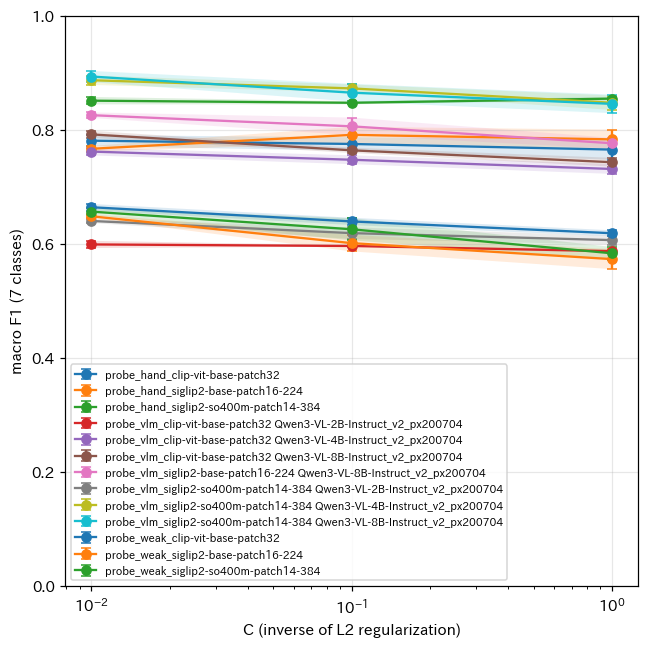

In [8]:
def plot_probe_c(df: pd.DataFrame, path: str) -> None:
    """線形プローブの手法について，C ごとのマクロ F1 の平均と標準偏差を描く．

    Args:
        df (pd.DataFrame): agg の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    probes = df[df["method"].str.startswith("probe")].copy()
    if probes.empty:
        return
    probes["C"] = probes["setting"].str.extract(r"C([0-9.]+)$").astype(float)
    probes["group"] = probes["method"] + probes["setting"].str.replace(r"_?C[0-9.]+$", "", regex=True).radd(" ").str.rstrip()
    fig, ax = plt.subplots(figsize=(6, 6))
    for g, d in probes.sort_values("C").groupby("group"):
        ax.errorbar(d["C"], d["flat_macro_f1_mean"], yerr=d["flat_macro_f1_std"], marker="o", capsize=3, label=g)
        ax.fill_between(d["C"], d["flat_macro_f1_mean"] - d["flat_macro_f1_std"], d["flat_macro_f1_mean"] + d["flat_macro_f1_std"], alpha=0.15)
    ax.set_xscale("log")
    ax.set_xlabel("C (inverse of L2 regularization)")
    ax.set_ylabel("macro F1 (7 classes)")
    ax.set_ylim(0, 1)
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


for ex in EXPERIMENTS:
    plot_probe_c(agg[agg["experiment"] == ex], os.path.join(OUTPUT_ROOT, ex, "figures", "fig_probe_C.png"))

## 混同行列（形式と画風）

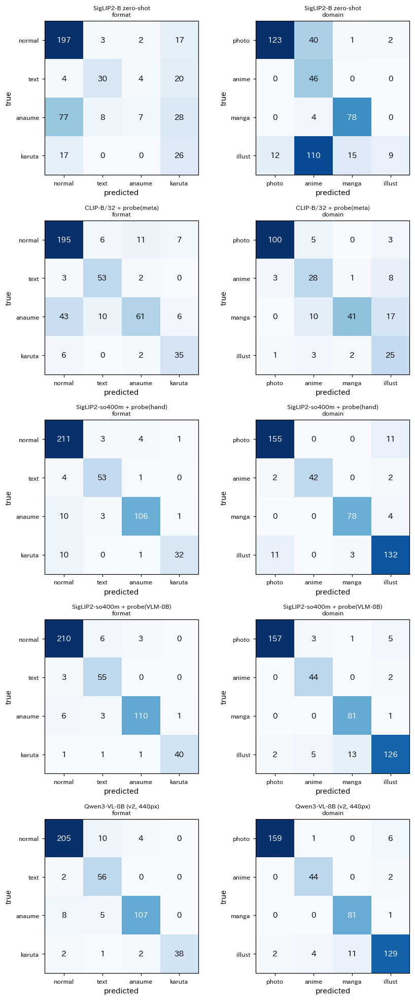

In [9]:
def confusion(pred: pd.DataFrame, true_col: str, pred_col: str, labels: list) -> np.ndarray:
    """混同行列（行が正解，列が予測）を求める．

    Args:
        pred (pd.DataFrame): predictions.csv の表．
        true_col (str): 正解の列名．
        pred_col (str): 予測の列名．
        labels (list[str]): クラス名のリスト．

    Returns:
        np.ndarray: 形状 (C, C) の件数の行列．
    """
    m = np.zeros((len(labels), len(labels)), dtype=int)
    for t, p in zip(pred[true_col], pred[pred_col]):
        if t in labels and p in labels:
            m[labels.index(t), labels.index(p)] += 1
    return m


def plot_confusions(df_best: pd.DataFrame, methods: list, path: str) -> None:
    """選んだ手法の形式と画風の混同行列を並べて描く（seed 0 の予測を用いる）．

    Args:
        df_best (pd.DataFrame): best の表．
        methods (list[str]): 手法名のリスト．
        path (str): 保存先のパス．

    Returns:
        None
    """
    fig, axes = plt.subplots(len(methods), 2, figsize=(8, 3.6 * len(methods)))
    axes = np.atleast_2d(axes)
    for row, method in zip(axes, methods):
        r = df_best[df_best["method"] == method].iloc[0]
        run_dir = runs[(runs["method"] == method) & (runs["setting"] == r["setting"]) & (runs["seed"] == 0)]["run_dir"].iloc[0]
        pred = pd.read_csv(os.path.join(run_dir, "predictions.csv"))
        for ax, (t, p, labels) in zip(row, [("true_format", "pred_format", FORMAT_LABELS), ("true_domain", "pred_domain", DOMAIN_LABELS)]):
            m = confusion(pred, t, p, labels)
            ax.imshow(m, cmap="Blues")
            for i, j in np.ndindex(m.shape):
                ax.text(j, i, m[i, j], ha="center", va="center", color="white" if m[i, j] > m.max() / 2 else "black")
            ax.set_xticks(range(len(labels)), labels, fontsize=8)
            ax.set_yticks(range(len(labels)), labels, fontsize=8)
            ax.set_xlabel("predicted")
            ax.set_ylabel("true")
            ax.set_title(f"{r['label']}\n{t.split('_')[1]}", fontsize=8)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


for ex in EXPERIMENTS:
    b = best[best["experiment"] == ex]
    if CONFUSION_METHODS is None:
        prefixes = ["zeroshot", "probe_weak", "probe_hand", "probe_vlm", "vlm", "ocr"]
        methods = [b[b["method"].str.startswith(p + "_")].iloc[0]["method"] for p in prefixes if (b["method"].str.startswith(p + "_")).any()]
        methods = [m for m in methods if not m.startswith("ocr")]
    else:
        methods = CONFUSION_METHODS
    plot_confusions(b, methods, os.path.join(OUTPUT_ROOT, ex, "figures", "fig_confusion.png"))

## 実際の画像による予測例

各クラスから画像を選び，正解のラベルと各手法の予測を示す．予測が正解と異なる場合は赤字で示す．

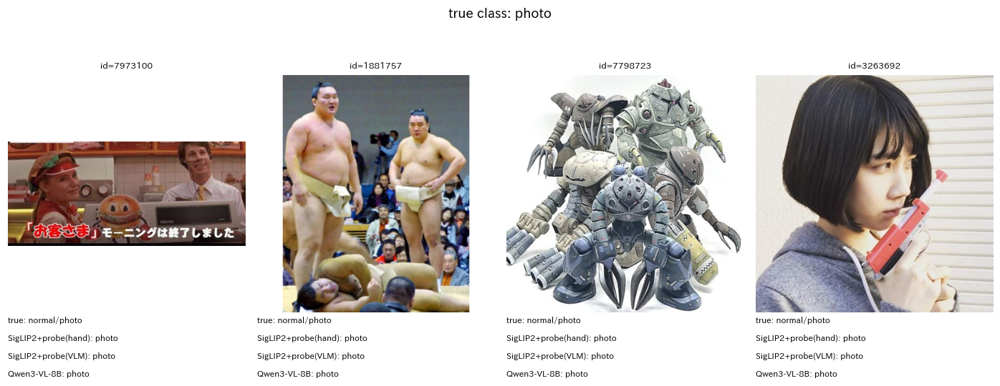

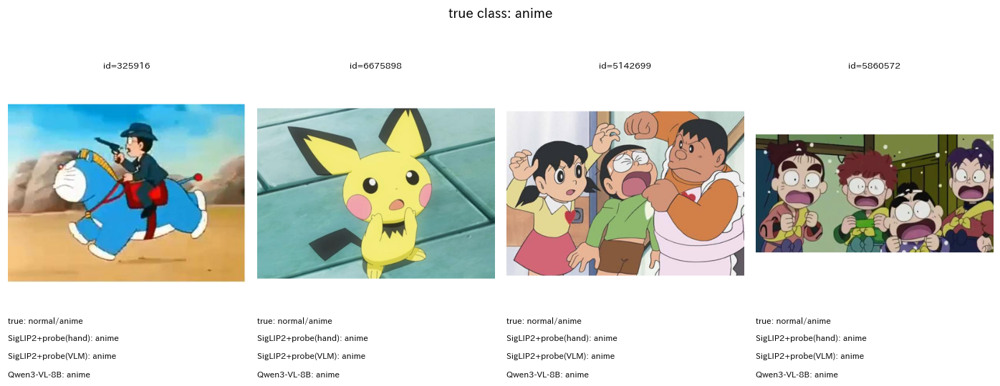

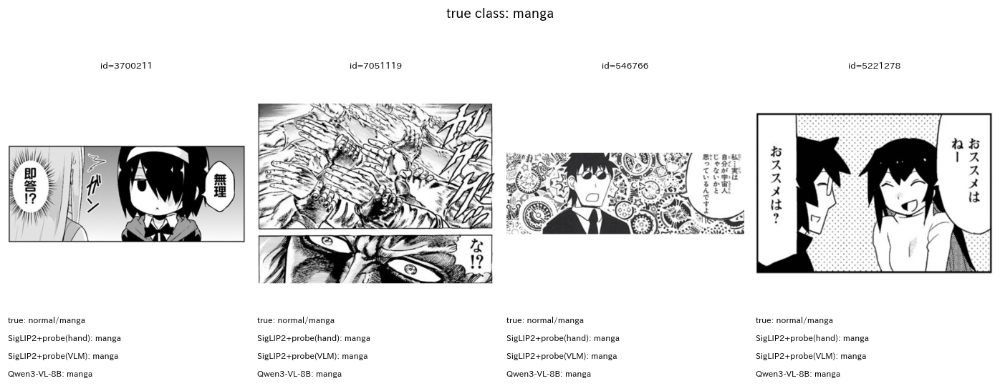

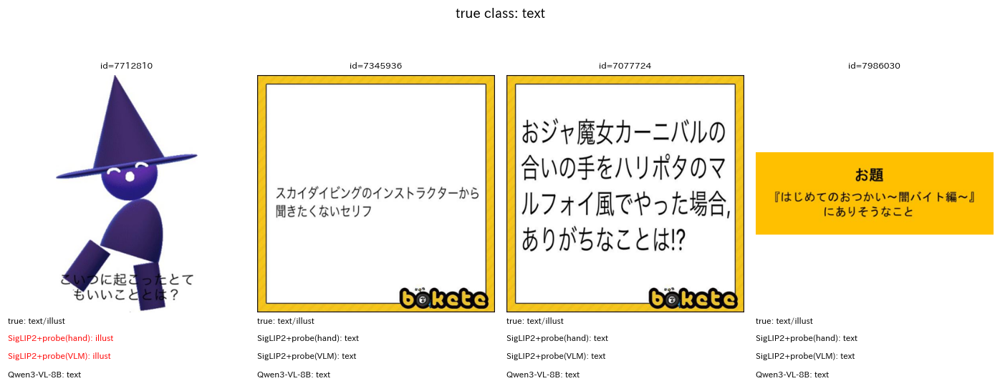

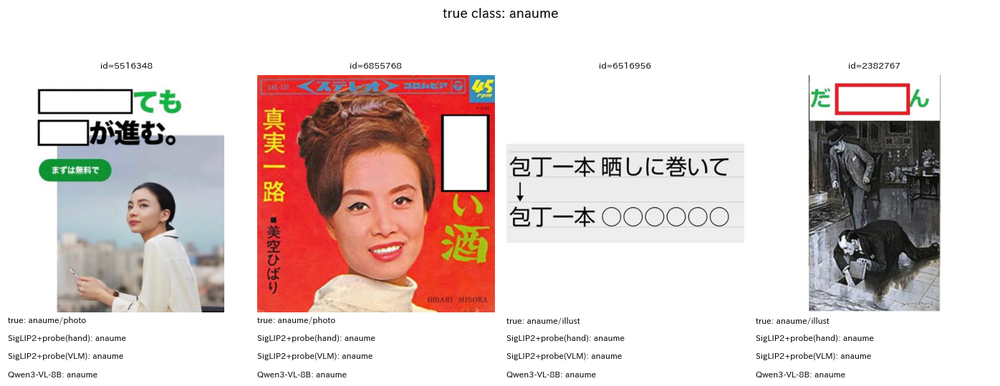

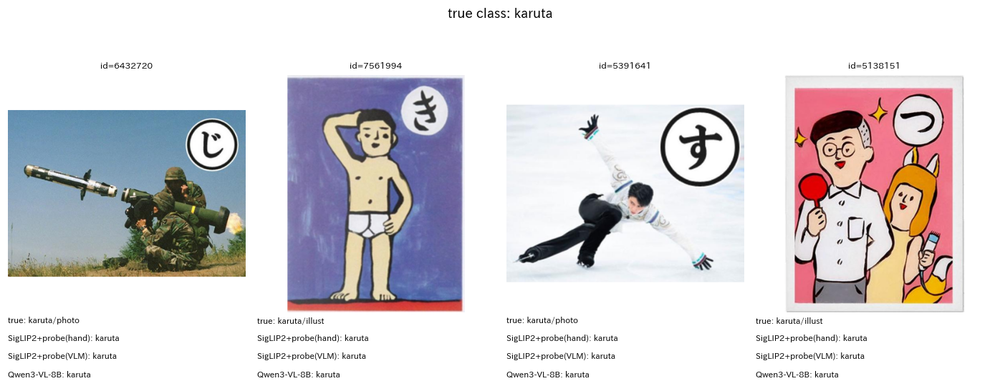

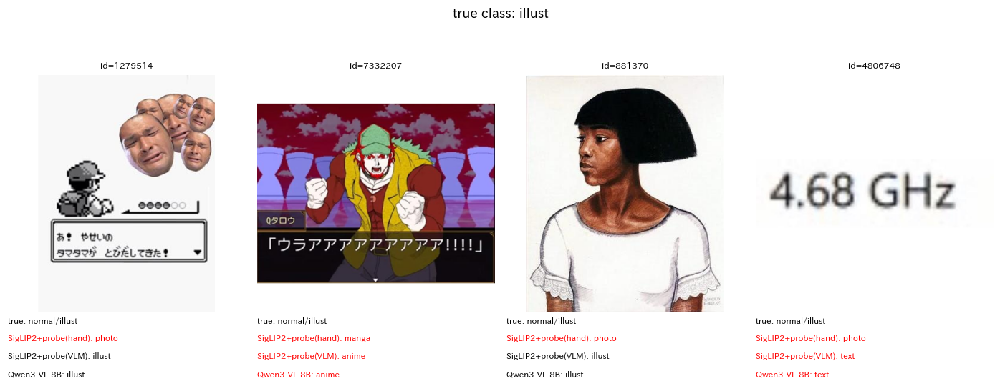

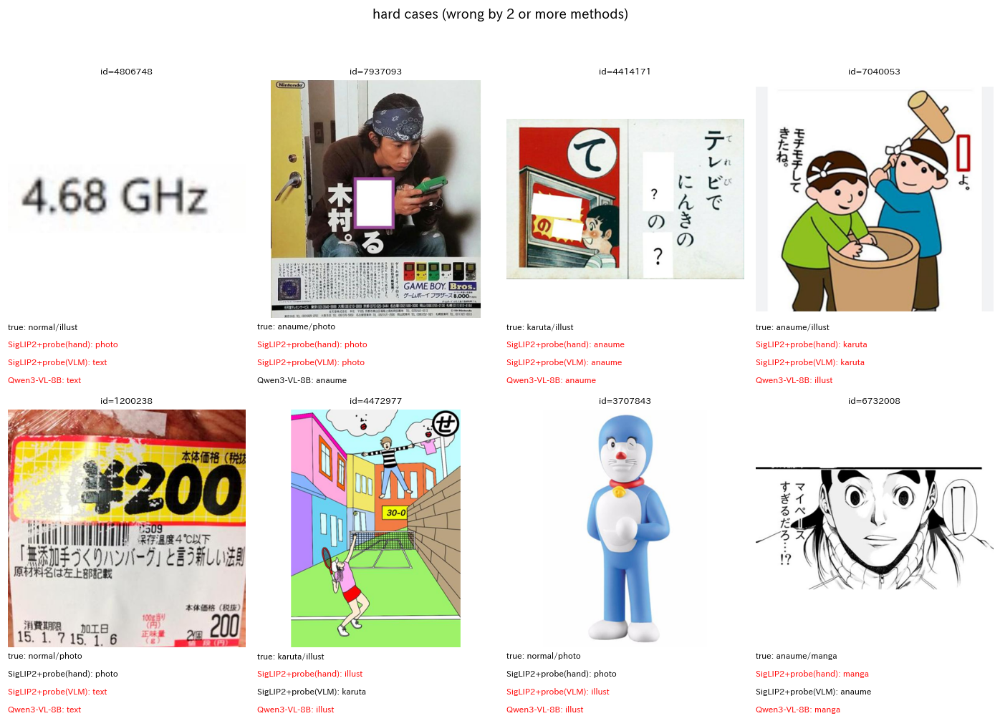

In [10]:
def image_path(odai_id: int) -> str:
    """お題IDから画像のパスを求める．

    Args:
        odai_id (int): お題ID．

    Returns:
        str: 画像のパス．
    """
    return os.path.join(IMAGE_DIR, str(odai_id // 10000 * 10000), f"{odai_id}.jpg")


def load_example_predictions(experiment: str) -> pd.DataFrame:
    """EXAMPLE_METHODS の各手法の予測（seed 0）を1つの表にまとめる．

    Args:
        experiment (str): 実験のディレクトリ名．

    Returns:
        pd.DataFrame: fileId，正解のラベル，各手法の予測（列名は表示名）を持つ表．
    """
    merged = None
    for name, (method, setting) in EXAMPLE_METHODS.items():
        if setting is None:
            setting = best[(best["experiment"] == experiment) & (best["method"] == method)]["setting"].iloc[0]
        p = pd.read_csv(os.path.join(OUTPUT_ROOT, experiment, method, setting, "0", "predictions.csv"))
        p = p[["fileId", "pool", "true_flat", "true_format", "true_domain", "pred_flat"]].rename(columns={"pred_flat": name})
        merged = p if merged is None else merged.merge(p[["fileId", name]], on="fileId")
    return merged


def square_image(path: str, size: int = 400) -> Image.Image:
    """画像を縦横比を保って正方形の白い余白に収める．

    Args:
        path (str): 画像のパス．
        size (int): 一辺の画素数．

    Returns:
        PIL.Image.Image: size×size の RGB 画像．
    """
    im = Image.open(path).convert("RGB")
    im.thumbnail((size, size))
    canvas = Image.new("RGB", (size, size), "white")
    canvas.paste(im, ((size - im.width) // 2, (size - im.height) // 2))
    return canvas


def plot_examples(df: pd.DataFrame, title: str, path: str, ncols: int = 4) -> None:
    """画像と，正解・各手法の予測を格子状に描く．

    Args:
        df (pd.DataFrame): load_example_predictions の表の一部．
        title (str): 図の題．
        path (str): 保存先のパス．
        ncols (int): 列数．

    Returns:
        None
    """
    nrows = int(np.ceil(len(df) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 4.6 * nrows))
    for ax in np.ravel(axes):
        ax.axis("off")
    for ax, (_, r) in zip(np.ravel(axes), df.iterrows()):
        ax.imshow(square_image(image_path(int(r["fileId"]))))
        lines = [(f"true: {r['true_format']}/{r['true_domain']}", "black")]
        lines += [(f"{n}: {r[n]}", "black" if r[n] == r["true_flat"] else "red") for n in EXAMPLE_METHODS]
        for k, (s, c) in enumerate(lines):
            ax.text(0, -0.02 - 0.075 * k, s, transform=ax.transAxes, va="top", fontsize=7.5, color=c)
        ax.set_title(f"id={int(r['fileId'])}", fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight", dpi=90)
    plt.show()


for ex in EXPERIMENTS:
    ex_pred = load_example_predictions(ex)
    names = list(EXAMPLE_METHODS)
    for cls in FLAT_LABELS:
        d = ex_pred[ex_pred["true_flat"] == cls].sample(n=min(4, (ex_pred["true_flat"] == cls).sum()), random_state=0)
        plot_examples(d, f"true class: {cls}", os.path.join(OUTPUT_ROOT, ex, "figures", f"fig_examples_{cls}.png"))
    wrong = ex_pred[(ex_pred[names].ne(ex_pred["true_flat"], axis=0)).sum(axis=1) >= 2].sample(n=8, random_state=0)
    plot_examples(wrong, "hard cases (wrong by 2 or more methods)", os.path.join(OUTPUT_ROOT, ex, "figures", "fig_examples_hard.png"))

## VLM による記号の位置の検出（グラウンディング）

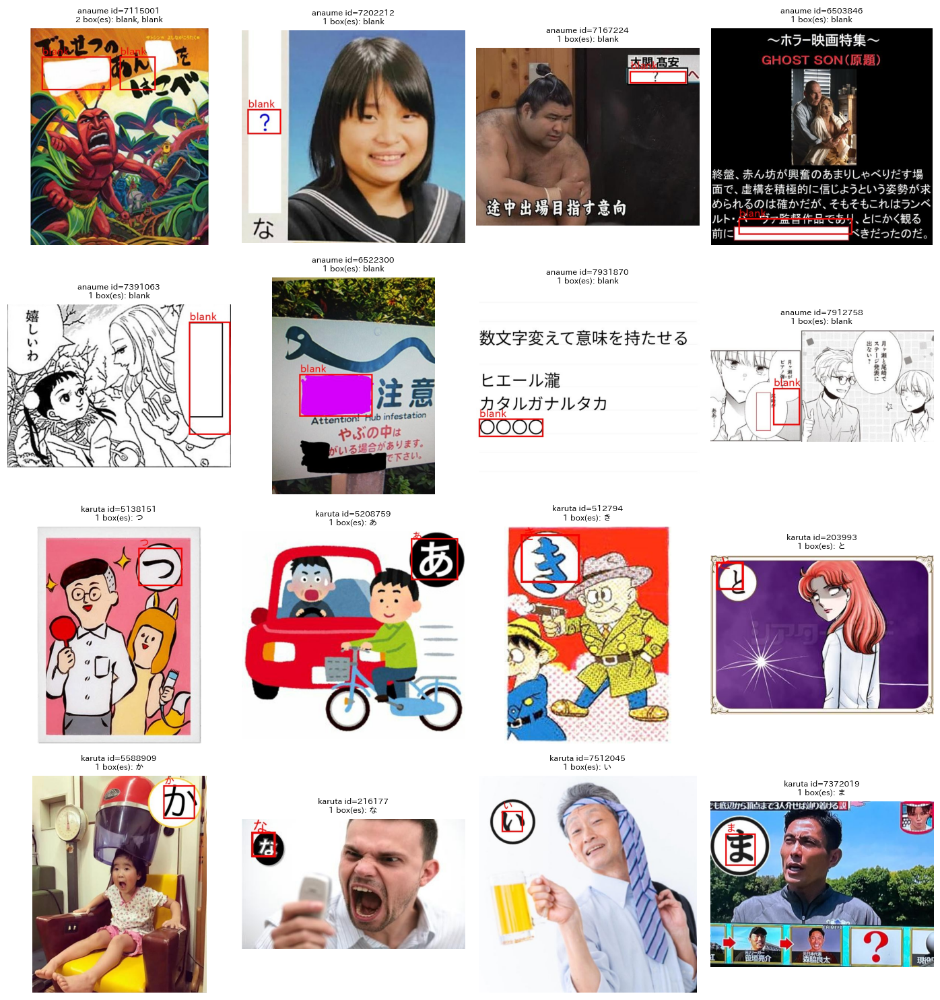

In [11]:
for ex in EXPERIMENTS:
    for res_path in glob.glob(os.path.join(OUTPUT_ROOT, ex, "grounding", "*", "0", "results.json")):
        res = json.load(open(res_path))
        d = os.path.dirname(res_path)
        ncols = 4
        nrows = int(np.ceil(len(res) / ncols))
        fig, axes = plt.subplots(nrows, ncols, figsize=(3.2 * ncols, 3.4 * nrows))
        for ax in np.ravel(axes):
            ax.axis("off")
        for ax, r in zip(np.ravel(axes), res):
            ax.imshow(Image.open(os.path.join(d, f"{r['format']}_{r['fileId']}.jpg")))
            labels = ", ".join(str(b.get("label", "")) for b in r["boxes"])
            ax.set_title(f"{r['format']} id={r['fileId']}\n{len(r['boxes'])} box(es): {labels[:20]}", fontsize=8)
        fig.tight_layout()
        fig.savefig(os.path.join(OUTPUT_ROOT, ex, "figures", "fig_grounding.png"), bbox_inches="tight", dpi=90)
        plt.show()

# ex002：教師・データ・生徒・構成の比較

`outputs/ex002_odai_type_distill/` を走査し，seed 間の平均と標準偏差を求めて可視化する．
評価用データは目視ラベルの640枚（うち無作為抽出440枚）である．ハイパーパラメータは教師ラベルの検証用分割で選んでいる．

In [12]:
EX2 = "ex002_odai_type_distill"
EX2_DIR = os.path.join(OUTPUT_ROOT, EX2)
FIG2 = os.path.join(EX2_DIR, "figures")
os.makedirs(FIG2, exist_ok=True)
EMBED_SPEED = {"siglip2-so400m-patch14-384": 177.5, "siglip2-base-patch16-224": 881.5, "clip-vit-base-patch32": 1087.4}
FEAT_SHORT = {"siglip2-so400m-patch14-384": "SigLIP2-so400m", "siglip2-base-patch16-224": "SigLIP2-B",
              "clip-vit-base-patch32": "CLIP-B/32", "blankbox": "BlankBox"}
TEACHER_SPEED = {}  # 教師の短い名前 -> 4万枚のラベル付けでの枚/秒（なければ評価用での値）


def speed_of(meta: dict) -> float:
    """meta.json から処理速度（枚/秒）を求める．生徒は特徴の中で最も遅い埋め込みの速度とする．

    Args:
        meta (dict): meta.json の内容．

    Returns:
        float: 1秒あたりの処理枚数．求められない場合は NaN．
    """
    for k in ["throughput_pool", "throughput", "throughput_eval"]:
        if k in meta:
            return meta[k]["images_per_sec"]
    feats = [f for f in meta.get("features", []) if f in EMBED_SPEED]
    return min(EMBED_SPEED[f] for f in feats) if feats else np.nan


def load_runs2() -> pd.DataFrame:
    """ex002 の全実行の指標を1行1実行の表に読み込む．

    Returns:
        pd.DataFrame: 列 method, setting, seed，評価用・無作為抽出・検証用の指標，処理速度を持つ表．
    """
    rows = []
    for path in glob.glob(os.path.join(EX2_DIR, "*", "*", "*", "metrics.json")):
        seed_dir = os.path.dirname(path)
        setting_dir = os.path.dirname(seed_dir)
        m = json.load(open(path))
        meta = json.load(open(os.path.join(seed_dir, "meta.json")))
        r = {"method": os.path.basename(os.path.dirname(setting_dir)), "setting": os.path.basename(setting_dir),
             "seed": os.path.basename(seed_dir), "run_dir": seed_dir, "images_per_sec": speed_of(meta),
             "n_train": meta.get("n_train"), "teacher": meta.get("teacher"), "features": "+".join(meta.get("features", []))}
        for part in ["eval", "eval_random"]:
            for k, v in m[part].items():
                if k != "per_class":
                    r[f"{part}_{k}"] = v
            for c in FLAT_LABELS:
                r[f"{part}_f1_{c}"] = m[part]["per_class"][c]["f1-score"]
        for part in ["train", "val"]:
            if isinstance(m.get(part), dict):
                for k, v in m[part].items():
                    if not isinstance(v, dict):
                        r[f"{part}_{k}"] = v
        if "hours" not in r and "throughput" in meta and "est_hours_all" in meta["throughput"]:
            r["hours"] = meta["throughput"]["est_hours_all"]
        rows.append(r)
    df = pd.DataFrame(rows)
    df["hours"] = df.get("hours", pd.Series(np.nan, index=df.index)).fillna(6_823_270 / df["images_per_sec"] / 3600)
    return df


runs2 = load_runs2()
num_cols = [c for c in runs2.columns if c.startswith(("eval", "val_", "train_")) or c in ["images_per_sec", "hours"]]
agg2 = runs2.groupby(["method", "setting"])[num_cols].agg(["mean", "std"])
agg2.columns = [f"{a}_{b}" for a, b in agg2.columns]
agg2 = agg2.reset_index()
agg2["n_seeds"] = runs2.groupby(["method", "setting"]).size().values
agg2.to_csv(os.path.join(FIG2, "summary_all.csv"), index=False)
show = ["method", "setting", "n_seeds", "eval_flat_accuracy_mean", "eval_flat_accuracy_std", "eval_flat_macro_f1_mean",
        "eval_random_flat_accuracy_mean", "val_flat_macro_f1_mean", "images_per_sec_mean", "hours_mean"]
agg2[[c for c in show if c in agg2.columns]].sort_values("eval_flat_macro_f1_mean", ascending=False).round(3)

,method,setting,n_seeds,eval_flat_accuracy_mean,eval_flat_accuracy_std,eval_flat_macro_f1_mean,eval_random_flat_accuracy_mean,val_flat_macro_f1_mean,images_per_sec_mean,hours_mean
11,cascade_logreg,Qwen3-VL-8B-Instruct__siglip2-so400m-patch14-3...,3,0.931,0.000,0.913,0.943,NaN,74.894,25.307
10,cascade_logreg,Qwen3-VL-8B-Instruct__siglip2-so400m-patch14-3...,3,0.928,0.000,0.910,0.945,NaN,105.341,17.993
12,cascade_logreg,Qwen3-VL-8B-Instruct__siglip2-so400m-patch14-3...,3,0.923,0.000,0.907,0.936,NaN,58.101,32.621
4,cascade_finetune_siglip2_base,Qwen3-VL-8B-Instruct_lr3e-05_ep5__Qwen3-VL-8B-...,3,0.922,0.004,0.903,0.934,NaN,116.232,16.307
3,cascade_finetune_siglip2_base,Qwen3-VL-8B-Instruct_lr3e-05_ep5__Qwen3-VL-8B-...,3,0.921,0.009,0.902,0.931,NaN,210.795,8.991
...,...,...,...,...,...,...,...,...,...,...
40,student_logreg,Qwen3-VL-8B-Instruct__siglip2-so400m-patch14-3...,3,0.841,0.006,0.752,0.895,0.747,177.500,10.678
59,teacher_InternVL3_5-8B,v2,1,0.794,NaN,0.742,0.791,NaN,5.099,371.685
32,student_knn,Qwen3-VL-8B-Instruct__siglip2-so400m-patch14-3...,3,0.811,0.000,0.702,0.850,0.715,177.500,10.678
60,teacher_MiniCPM-V-4_5,v2,1,0.684,NaN,0.572,0.714,NaN,13.296,142.547


## 教師 VLM の比較

横軸は1秒あたりの処理枚数（対数軸），縦軸は7クラスのマクロ F1 である．

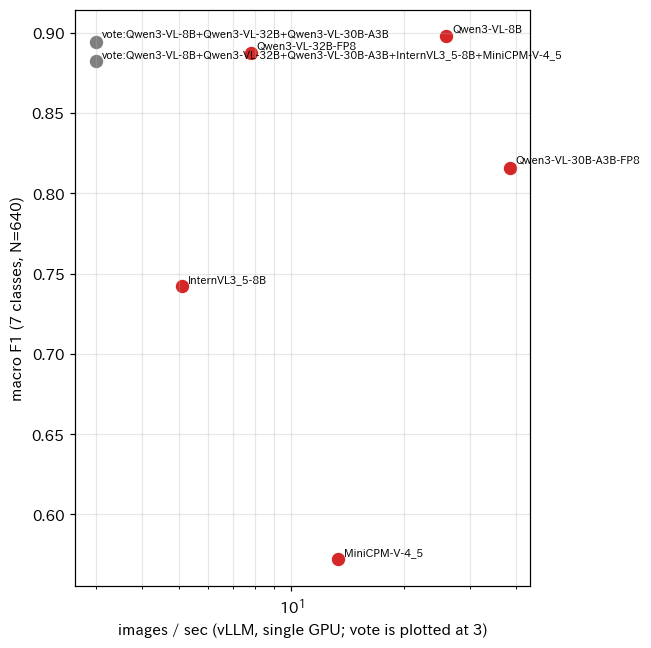

,method,setting,eval_flat_accuracy_mean,eval_flat_macro_f1_mean,eval_random_flat_accuracy_mean,eval_format_accuracy_mean,eval_domain_accuracy_mean,images_per_sec_mean,hours_mean
59,teacher_InternVL3_5-8B,v2,0.794,0.742,0.791,0.834,0.859,5.099,371.685
60,teacher_MiniCPM-V-4_5,v2,0.684,0.572,0.714,0.692,0.928,13.296,142.547
61,teacher_Qwen3-VL-30B-A3B-Instruct-FP8,v2,0.861,0.816,0.873,0.892,0.894,38.376,49.389
62,teacher_Qwen3-VL-32B-Instruct-FP8,v2,0.916,0.887,0.909,0.941,0.933,7.790,243.320
63,teacher_Qwen3-VL-8B-Instruct,v2,0.916,0.898,0.927,0.930,0.942,25.912,73.145
64,teacher_vote,vote_Qwen3-VL-8B+Qwen3-VL-32B+Qwen3-VL-30B-A3B,0.922,0.894,0.920,0.944,0.931,NaN,NaN
65,teacher_vote,vote_Qwen3-VL-8B+Qwen3-VL-32B+Qwen3-VL-30B-A3B...,0.911,0.882,0.911,0.930,0.936,NaN,NaN


In [13]:
def plot_teachers(df: pd.DataFrame, path: str) -> None:
    """教師 VLM の処理速度とマクロ F1（全640枚と無作為抽出440枚の正解率）を描く．

    Args:
        df (pd.DataFrame): agg2 のうち教師の行．
        path (str): 保存先のパス．

    Returns:
        None
    """
    fig, ax = plt.subplots(figsize=(6, 6))
    for _, r in df.iterrows():
        name = (r["setting"] if r["method"] == "teacher_vote" else r["method"].replace("teacher_", "")).replace("-Instruct", "")
        ax.scatter(r["images_per_sec_mean"] if not np.isnan(r["images_per_sec_mean"]) else 3, r["eval_flat_macro_f1_mean"],
                   s=60, color="#d62728" if r["method"] != "teacher_vote" else "#7f7f7f")
        ax.annotate(name.replace("vote_", "vote:"), (r["images_per_sec_mean"] if not np.isnan(r["images_per_sec_mean"]) else 3,
                    r["eval_flat_macro_f1_mean"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("images / sec (vLLM, single GPU; vote is plotted at 3)")
    ax.set_ylabel("macro F1 (7 classes, N=640)")
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


teachers2 = agg2[agg2["method"].str.startswith("teacher")]
plot_teachers(teachers2, os.path.join(FIG2, "fig_teachers.png"))
teachers2[["method", "setting", "eval_flat_accuracy_mean", "eval_flat_macro_f1_mean", "eval_random_flat_accuracy_mean",
           "eval_format_accuracy_mean", "eval_domain_accuracy_mean", "images_per_sec_mean", "hours_mean"]].round(3)

## 生徒の比較（教師は Qwen3-VL-8B，学習は無作為抽出の36,000枚）

横軸は7クラスの正解率とマクロ F1，誤差棒は seed 間の標準偏差である．

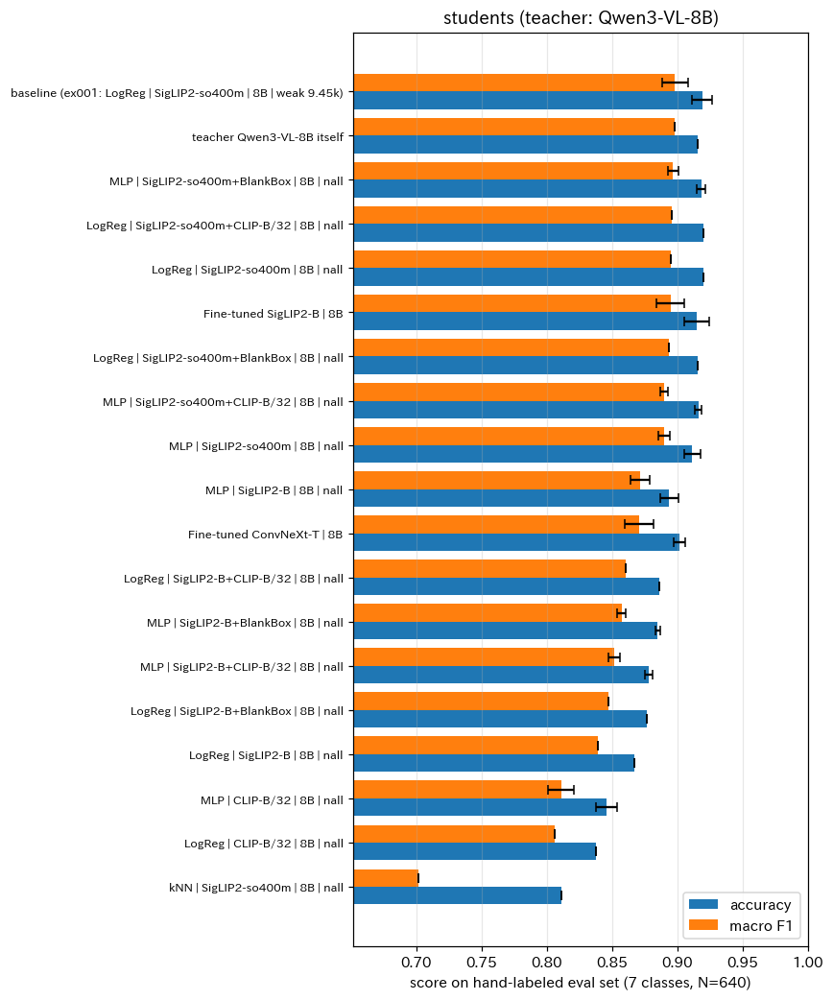

In [14]:
def student_label(method: str, setting: str) -> str:
    """生徒の行の表示名を作る．

    Args:
        method (str): 手法名．
        setting (str): 設定名（{教師}__{特徴}__n{枚数}）．

    Returns:
        str: 例 "MLP | SigLIP2-so400m+BlankBox | 8B | n=all"．
    """
    if not method.startswith("student_"):
        short = {"finetune_siglip2_base": "Fine-tuned SigLIP2-B | 8B", "finetune_convnext_tiny": "Fine-tuned ConvNeXt-T | 8B",
                 "baseline_ex001": "baseline (ex001: LogReg | SigLIP2-so400m | 8B | weak 9.45k)",
                 "teacher_Qwen3-VL-8B-Instruct": "teacher Qwen3-VL-8B itself"}
        return short.get(method, f"{method} [{setting}]")
    teacher, feats, n = setting.split("__")
    kind = {"student_logreg": "LogReg", "student_mlp": "MLP", "student_knn": "kNN"}[method]
    feats = "+".join(FEAT_SHORT.get(f, f) for f in feats.split("+"))
    return f"{kind} | {feats} | {teacher.replace('-Instruct', '').replace('Qwen3-VL-', '')} | {n}"


agg2["label"] = [student_label(m, s) for m, s in zip(agg2["method"], agg2["setting"])]


def plot_bars(df: pd.DataFrame, path: str, title: str) -> None:
    """正解率とマクロ F1 の横棒グラフを描く．

    Args:
        df (pd.DataFrame): agg2 の一部．
        path (str): 保存先のパス．
        title (str): 図の題．

    Returns:
        None
    """
    df = df.sort_values("eval_flat_macro_f1_mean")
    y = np.arange(len(df))
    fig, ax = plt.subplots(figsize=(8, 0.42 * len(df) + 1.6))
    ax.barh(y - 0.2, df["eval_flat_accuracy_mean"], 0.4, xerr=df["eval_flat_accuracy_std"].fillna(0), capsize=3, label="accuracy")
    ax.barh(y + 0.2, df["eval_flat_macro_f1_mean"], 0.4, xerr=df["eval_flat_macro_f1_std"].fillna(0), capsize=3, label="macro F1")
    ax.set_yticks(y, df["label"], fontsize=8)
    lo = max(0.0, min(df["eval_flat_macro_f1_mean"].min(), df["eval_flat_accuracy_mean"].min()) - 0.05)
    ax.set_xlim(lo, 1.0)
    ax.set_xlabel("score on hand-labeled eval set (7 classes, N=640)")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


main_t = "Qwen3-VL-8B-Instruct"
stud = agg2[agg2["method"].str.startswith("student_") & agg2["setting"].str.startswith(main_t + "__") & agg2["setting"].str.endswith("__nall")]
ref = agg2[agg2["method"].isin(["baseline_ex001", "teacher_Qwen3-VL-8B-Instruct"]) | agg2["method"].str.startswith("finetune_")]
# 微調整は手法ごとに検証用（教師ラベル）の正解率が最良の学習率のみを示す
ft = ref[ref["method"].str.startswith("finetune_")]
ref = pd.concat([ref[~ref["method"].str.startswith("finetune_")],
                 ft.loc[ft.groupby("method")["val_flat_accuracy_mean"].idxmax()] if not ft.empty else ft])
plot_bars(pd.concat([stud, ref]), os.path.join(FIG2, "fig_students.png"), "students (teacher: Qwen3-VL-8B)")

## 教師の違いによる生徒の精度

横軸は教師自身の7クラスの正解率，縦軸は同じ教師のラベルで学習した生徒（SigLIP2-so400m の特徴）の正解率である．破線は y = x．

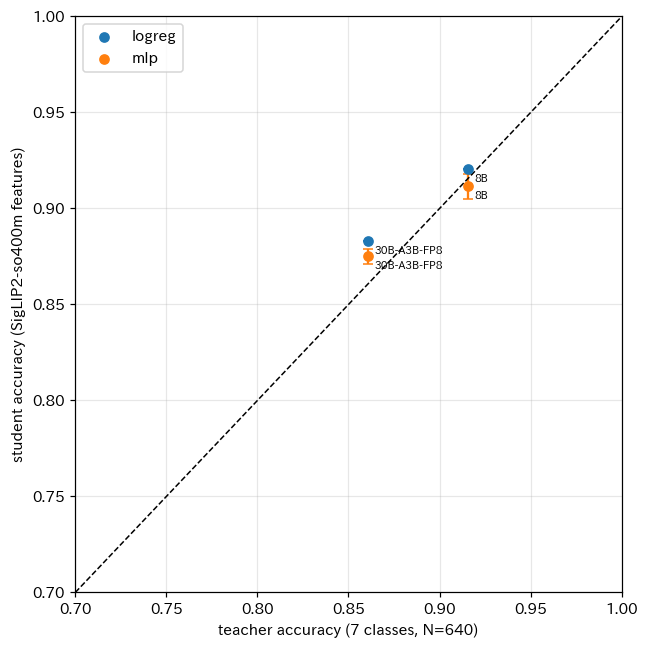

In [15]:
def plot_teacher_effect(path: str) -> None:
    """教師の正解率と，その教師で学習した生徒の正解率の関係を描く．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    fig, ax = plt.subplots(figsize=(6, 6))
    for kind, color in [("student_logreg", "#1f77b4"), ("student_mlp", "#ff7f0e")]:
        d = agg2[(agg2["method"] == kind) & agg2["setting"].str.contains("__siglip2-so400m-patch14-384__nall")]
        for _, r in d.iterrows():
            t = r["setting"].split("__")[0]
            tr = agg2[(agg2["method"] == f"teacher_{t}") | ((agg2["method"] == "teacher_vote") & (agg2["setting"] == t))]
            if tr.empty:
                continue
            x = tr["eval_flat_accuracy_mean"].iloc[0]
            ax.errorbar(x, r["eval_flat_accuracy_mean"], yerr=r["eval_flat_accuracy_std"], fmt="o", color=color, capsize=3)
            ax.annotate(t.replace("-Instruct", "").replace("Qwen3-VL-", ""), (x, r["eval_flat_accuracy_mean"]), fontsize=7,
                        xytext=(4, -8), textcoords="offset points")
        ax.scatter([], [], color=color, label=kind.replace("student_", ""))
    lims = [0.7, 1.0]
    ax.plot(lims, lims, "k--", lw=1)
    ax.set_xlim(*lims)
    ax.set_ylim(*lims)
    ax.set_xlabel("teacher accuracy (7 classes, N=640)")
    ax.set_ylabel("student accuracy (SigLIP2-so400m features)")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_teacher_effect(os.path.join(FIG2, "fig_teacher_effect.png"))

## 学習枚数による変化（学習曲線）

横軸は教師ラベルの学習枚数（対数軸），縦軸は7クラスのマクロ F1 である．実線は評価用データ（目視ラベル），破線は検証用分割（教師ラベル）．

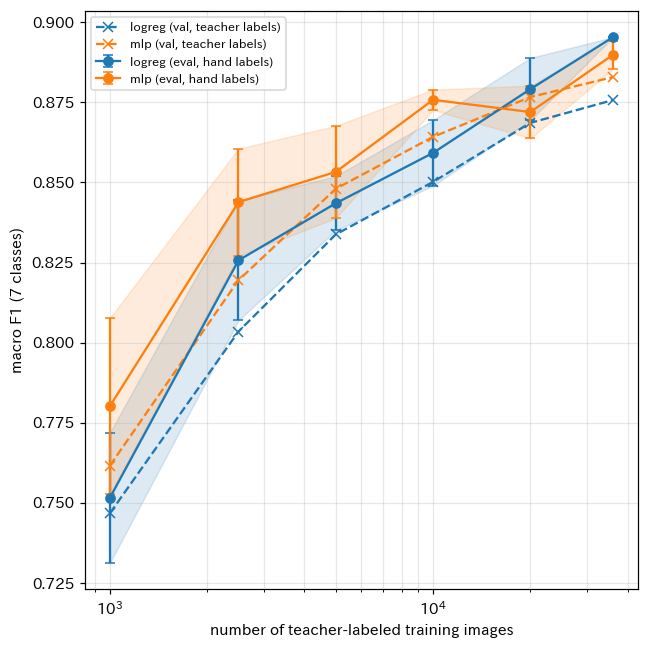

In [16]:
def plot_learning_curve(path: str) -> None:
    """学習枚数と精度の関係を描く．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    fig, ax = plt.subplots(figsize=(6, 6))
    for kind, color in [("student_logreg", "#1f77b4"), ("student_mlp", "#ff7f0e")]:
        d = agg2[(agg2["method"] == kind) & agg2["setting"].str.startswith(main_t + "__siglip2-so400m-patch14-384__n")].copy()
        d["n"] = d["setting"].str.extract(r"__n(\w+)$")[0].replace({"all": "36000"}).astype(int)
        d = d.sort_values("n")
        ax.errorbar(d["n"], d["eval_flat_macro_f1_mean"], yerr=d["eval_flat_macro_f1_std"], marker="o", color=color,
                    capsize=3, label=f"{kind.replace('student_', '')} (eval, hand labels)")
        ax.fill_between(d["n"], d["eval_flat_macro_f1_mean"] - d["eval_flat_macro_f1_std"],
                        d["eval_flat_macro_f1_mean"] + d["eval_flat_macro_f1_std"], color=color, alpha=0.15)
        ax.plot(d["n"], d["val_flat_macro_f1_mean"], ls="--", marker="x", color=color,
                label=f"{kind.replace('student_', '')} (val, teacher labels)")
    ax.set_xscale("log")
    ax.set_xlabel("number of teacher-labeled training images")
    ax.set_ylabel("macro F1 (7 classes)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_learning_curve(os.path.join(FIG2, "fig_learning_curve.png"))

## カスケード（確信度の低い画像を教師で再判定）

横軸は教師で再判定する画像の割合，縦軸は7クラスの正解率である．上側の軸は全件の処理時間の見積もり．

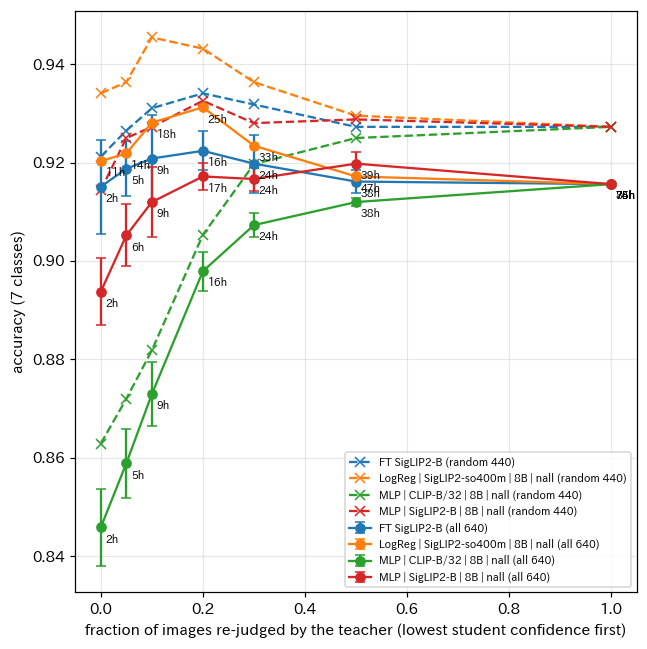

In [17]:
def cascade_label(s: str) -> str:
    """カスケードの生徒の表示名を作る．

    Args:
        s (str): "{手法} | {生徒の設定}" の形の文字列．

    Returns:
        str: 表示名．
    """
    kind, setting = s.split(" | ")
    if kind.startswith("finetune_"):
        return {"finetune_siglip2_base": "FT SigLIP2-B", "finetune_convnext_tiny": "FT ConvNeXt-T"}.get(kind, kind)
    return student_label("student_" + kind, setting)


def plot_cascade(path: str) -> None:
    """カスケードの再判定の割合と正解率の関係を描く．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    d = agg2[agg2["method"].str.startswith("cascade_")].copy()
    if d.empty:
        return
    d["frac"] = d["setting"].str.extract(r"_frac([0-9.]+)$")[0].astype(float)
    d["student"] = d["method"].str.replace("cascade_", "") + " | " + d["setting"].str.replace(r"__[^_]+_frac[0-9.]+$", "", regex=True)
    fig, ax = plt.subplots(figsize=(6, 6))
    for s, g in d.groupby("student"):
        g = g.sort_values("frac")
        eb = ax.errorbar(g["frac"], g["eval_flat_accuracy_mean"], yerr=g["eval_flat_accuracy_std"], marker="o", capsize=3,
                         label=cascade_label(s) + " (all 640)")
        ax.plot(g["frac"], g["eval_random_flat_accuracy_mean"], ls="--", marker="x", color=eb[0].get_color(),
                label=cascade_label(s) + " (random 440)")
        for _, r in g.iterrows():
            ax.annotate(f"{r['hours_mean']:.0f}h", (r["frac"], r["eval_flat_accuracy_mean"]), fontsize=7,
                        xytext=(3, -10), textcoords="offset points")
    ax.set_xlabel("fraction of images re-judged by the teacher (lowest student confidence first)")
    ax.set_ylabel("accuracy (7 classes)")
    ax.legend(fontsize=7)
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_cascade(os.path.join(FIG2, "fig_cascade.png"))

## 微調整の学習曲線

横軸はエポック（0は学習前），縦軸は誤差（左）と7クラスの正解率（右）である．実線が学習用，破線が検証用（教師ラベル），塗りつぶしは seed 間の標準偏差．

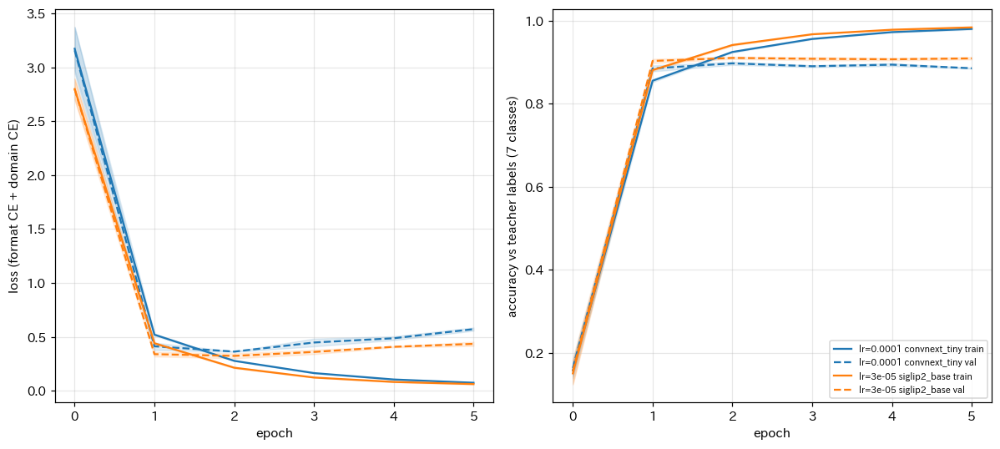

In [18]:
def plot_finetune(path: str) -> None:
    """微調整の log.json から誤差と正解率の推移を描く．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    logs = {}
    for p in glob.glob(os.path.join(EX2_DIR, "finetune_*", "*", "*", "log.json")):
        key = p.split(os.sep)[-4].replace("finetune_", "") + " " + p.split(os.sep)[-3].split("_lr")[1].split("_ep")[0]
        logs.setdefault(key, []).append(json.load(open(p)))
    if not logs:
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for (key, ls_), color in zip(sorted(logs.items()), plt.rcParams["axes.prop_cycle"].by_key()["color"]):
        for ax, metric in zip(axes, ["loss", "flat_accuracy"]):
            for split, style in [("train", "-"), ("val", "--")]:
                a = np.array([l[f"{split}_{metric}"] for l in ls_])
                x = np.arange(a.shape[1])
                ax.plot(x, a.mean(0), style, color=color, label=f"lr={key.split()[1]} {key.split()[0]} {split}")
                ax.fill_between(x, a.mean(0) - a.std(0), a.mean(0) + a.std(0), color=color, alpha=0.12)
    axes[0].set_ylabel("loss (format CE + domain CE)")
    axes[1].set_ylabel("accuracy vs teacher labels (7 classes)")
    for ax in axes:
        ax.set_xlabel("epoch")
        ax.grid(alpha=0.3)
    axes[1].legend(fontsize=7)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_finetune(os.path.join(FIG2, "fig_finetune_curve.png"))

## 全手法の処理速度と精度

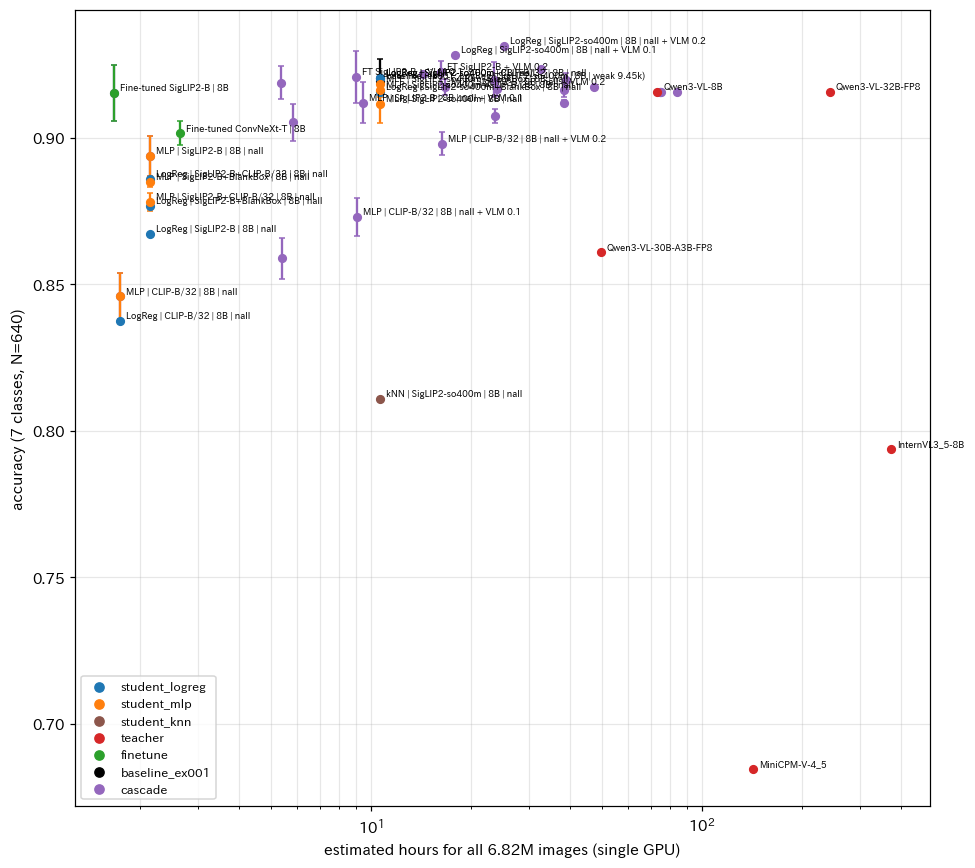

In [19]:
def plot_overall(path: str) -> None:
    """ex002 の主な手法の処理時間と正解率を描く．生徒は SigLIP2-so400m 以外の特徴も含め，教師は8Bのもののみ．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    fam = {"student_logreg": "#1f77b4", "student_mlp": "#ff7f0e", "student_knn": "#8c564b", "teacher_": "#d62728",
           "finetune_": "#2ca02c", "baseline_ex001": "#000000", "cascade_": "#9467bd"}
    d = agg2[(~agg2["method"].str.startswith("student_") | agg2["setting"].str.endswith("__nall"))
             & agg2["setting"].apply(lambda s: "__" not in s or s.startswith(main_t))
             & ~agg2["method"].isin(["teacher_vote", "rule_blankbox"])].copy()
    d = d[d["hours_mean"].notna()]
    fig, ax = plt.subplots(figsize=(9, 8))
    for _, r in d.iterrows():
        c = next(v for k, v in fam.items() if r["method"].startswith(k))
        ax.errorbar(r["hours_mean"], r["eval_flat_accuracy_mean"], yerr=r["eval_flat_accuracy_std"], fmt="o", color=c, capsize=2, ms=5)
    for _, r in d.iterrows():
        if r["method"].startswith("cascade_"):
            if not r["setting"].endswith(("_frac0.1", "_frac0.2")):
                continue
            name = cascade_label(r["method"].replace("cascade_", "") + " | " + r["setting"].split("__Qwen")[0]) +                 " + VLM " + r["setting"].split("_frac")[1]
        elif r["method"].startswith("teacher_"):
            name = r["method"].replace("teacher_", "").replace("-Instruct", "")
        else:
            name = r["label"]
        ax.annotate(name, (r["hours_mean"], r["eval_flat_accuracy_mean"]), fontsize=6, xytext=(4, 2), textcoords="offset points")
    for k, v in fam.items():
        ax.scatter([], [], color=v, label=k.rstrip("_"))
    ax.set_xscale("log")
    ax.set_xlabel("estimated hours for all 6.82M images (single GPU)")
    ax.set_ylabel("accuracy (7 classes, N=640)")
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_overall(os.path.join(FIG2, "fig_overall_speed.png"))

# ex004：確定版の定義（4軸）による蒸留

`outputs/ex004_four_axis_distill/` を走査し，seed 間の平均と標準偏差を求めて可視化する．
評価用データは確定版の定義で付け直した目視ラベルの640枚（うち無作為抽出440枚）である．
形式は正解率とマクロ F1，属性・媒体・事前知識は項目ごとの F1 の平均（マクロ F1）で評価する．

In [20]:
EX4_DIR = os.path.join(OUTPUT_ROOT, "ex004_four_axis_distill")
FIG4 = os.path.join(EX4_DIR, "figures")
os.makedirs(FIG4, exist_ok=True)
AXES4 = ["format", "attr", "media", "know"]
AXIS_JA = {"format": "形式", "attr": "属性", "media": "媒体", "know": "事前知識"}
EMBED_SPEED4 = {"siglip2-so400m-patch14-384": 177.5, "siglip2-base-patch16-224": 881.5, "clip-vit-base-patch32": 1087.4}


def load_runs4() -> pd.DataFrame:
    """ex004 の全実行の指標を1行1実行の表に読み込む．

    Returns:
        pd.DataFrame: 列 method, setting, seed，評価用・無作為抽出・学習用・検証用の指標，処理速度を持つ表．
    """
    rows = []
    for path in glob.glob(os.path.join(EX4_DIR, "*", "*", "*", "metrics.json")):
        seed_dir = os.path.dirname(path)
        m = json.load(open(path))
        meta = json.load(open(os.path.join(seed_dir, "meta.json")))
        r = {"method": seed_dir.split(os.sep)[-3], "setting": seed_dir.split(os.sep)[-2], "seed": seed_dir.split(os.sep)[-1],
             "run_dir": seed_dir}
        for part in ["eval", "eval_random"]:
            for k, v in m[part].items():
                if not isinstance(v, dict):
                    r[f"{part}_{k}"] = v
        for part in ["train", "val"]:
            for k, v in (m.get(part) or {}).items():
                if not isinstance(v, (dict, list)):
                    r[f"{part}_{k}"] = v
        ips = None
        for k in ["throughput_pool", "throughput", "throughput_eval"]:
            if k in meta:
                ips = meta[k]["images_per_sec"]
                break
        if ips is None and meta.get("features"):
            ips = EMBED_SPEED4.get(meta["features"][0])
        r["images_per_sec"] = ips
        rows.append(r)
    return pd.DataFrame(rows)


runs4 = load_runs4()
num4 = [c for c in runs4.columns if c.startswith(("eval", "train_", "val_")) or c == "images_per_sec"]
agg4 = runs4.groupby(["method", "setting"])[num4].agg(["mean", "std"])
agg4.columns = [f"{a}_{b}" for a, b in agg4.columns]
agg4 = agg4.reset_index()
agg4["n_seeds"] = runs4.groupby(["method", "setting"]).size().values
agg4["hours_all"] = 6_823_270 / agg4["images_per_sec_mean"] / 3600


def label4(method: str, setting: str) -> str:
    """図に表示する短い手法名を作る．

    Args:
        method (str): 手法名．
        setting (str): 設定名．

    Returns:
        str: 表示名．
    """
    if method.startswith("teacher_Qwen"):
        return f"教師 8B {setting.replace('_rule_wu_boke', '+規則+ボケ').replace('_rule_wu', '+規則')}"
    if method == "teacher_hybrid":
        return "教師 組み合わせ（v2形式＋v5）"
    if method.startswith("finetune_"):
        t = "組み合わせ" if setting.startswith("hybrid") else "v5+規則"
        return f"微調整 SigLIP2-B（{t}）"
    kind = {"student_logreg": "LogReg", "student_mlp": "MLP"}[method]
    teacher, feat = setting.split("__")
    t = "組み合わせ" if teacher.startswith("hybrid") else "v5+規則"
    return f"{kind} {feat.replace('-patch14-384', '').replace('-patch16-224', '').replace('clip-vit-base-patch32', 'CLIP-B/32')}（{t}）"


agg4["label"] = [label4(m, s) for m, s in zip(agg4["method"], agg4["setting"])]
cols4 = ["label", "n_seeds", "eval_format_accuracy_mean", "eval_format_accuracy_std", "eval_format_macro_f1_mean",
         "eval_attr_macro_f1_mean", "eval_media_macro_f1_mean", "eval_know_macro_f1_mean", "eval_overall_macro_f1_mean",
         "eval_overall_macro_f1_std", "eval_random_format_accuracy_mean", "images_per_sec_mean", "hours_all"]
agg4 = agg4.sort_values("eval_overall_macro_f1_mean", ascending=False)
agg4[["method", "setting"] + cols4].to_csv(os.path.join(FIG4, "summary_all.csv"), index=False)
agg4[cols4].round(3)

,label,n_seeds,eval_format_accuracy_mean,eval_format_accuracy_std,eval_format_macro_f1_mean,eval_attr_macro_f1_mean,eval_media_macro_f1_mean,eval_know_macro_f1_mean,eval_overall_macro_f1_mean,eval_overall_macro_f1_std,eval_random_format_accuracy_mean,images_per_sec_mean,hours_all
13,MLP siglip2-so400m（組み合わせ）,3,0.918,0.002,0.896,0.781,0.781,0.652,0.778,0.002,0.918,177.500,10.678
21,教師 組み合わせ（v2形式＋v5）,1,0.922,NaN,0.904,0.781,0.729,0.671,0.771,NaN,0.930,NaN,NaN
7,LogReg siglip2-so400m（組み合わせ）,3,0.923,0.000,0.893,0.782,0.705,0.642,0.755,0.000,0.930,177.500,10.678
10,MLP siglip2-so400m（v5+規則）,3,0.888,0.011,0.857,0.773,0.721,0.669,0.755,0.007,0.883,177.500,10.678
20,教師 8B v5+規則+ボケ,1,0.878,NaN,0.849,0.766,0.729,0.671,0.754,NaN,0.873,NaN,NaN
12,MLP siglip2-base（組み合わせ）,3,0.899,0.004,0.871,0.769,0.741,0.622,0.751,0.009,0.910,881.500,2.150
1,微調整 SigLIP2-B（組み合わせ）,3,0.930,0.005,0.910,0.796,0.680,0.586,0.743,0.015,0.934,911.753,2.079
19,教師 8B v5+規則,1,0.866,NaN,0.816,0.744,0.729,0.671,0.740,NaN,0.864,NaN,NaN
9,MLP siglip2-base（v5+規則）,3,0.876,0.005,0.840,0.750,0.745,0.616,0.738,0.001,0.889,881.500,2.150
0,微調整 SigLIP2-B（v5+規則）,3,0.898,0.009,0.869,0.785,0.706,0.581,0.735,0.007,0.898,838.082,2.262


## 4軸のマクロ F1（seed 間の平均 ± 標準偏差）\n\n横軸は各軸のマクロ F1，色は軸を表す．

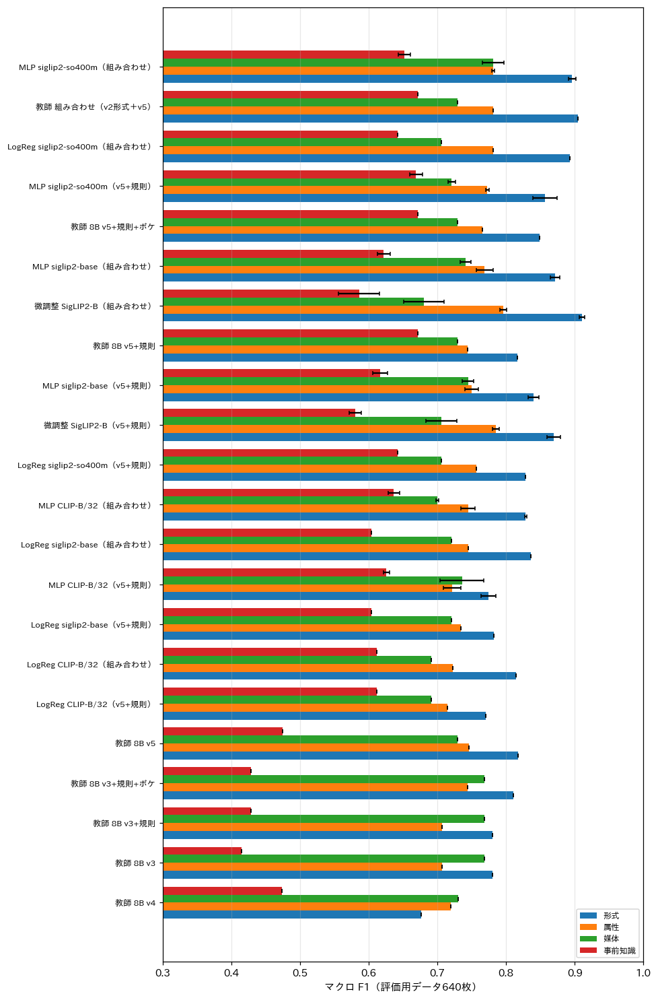

In [21]:
def plot_axes4(df: pd.DataFrame, path: str) -> None:
    """手法ごとに4軸のマクロ F1 を横棒グラフで描く．

    Args:
        df (pd.DataFrame): agg4 の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    df = df.sort_values("eval_overall_macro_f1_mean")
    y = np.arange(len(df))
    w = 0.2
    fig, ax = plt.subplots(figsize=(9, 0.55 * len(df) + 1.5))
    for i, a in enumerate(AXES4):
        ax.barh(y + (i - 1.5) * w, df[f"eval_{a}_macro_f1_mean"], w, xerr=df[f"eval_{a}_macro_f1_std"].fillna(0),
                capsize=2, label=AXIS_JA[a])
    ax.set_yticks(y, df["label"], fontsize=8)
    ax.set_xlim(0.3, 1.0)
    ax.set_xlabel("マクロ F1（評価用データ640枚）")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_axes4(agg4, os.path.join(FIG4, "fig_axes_f1.png"))

## 項目ごとの F1\n\n行は手法，列は形式のクラスと属性・媒体・事前知識の項目である（seed 0 の結果）．

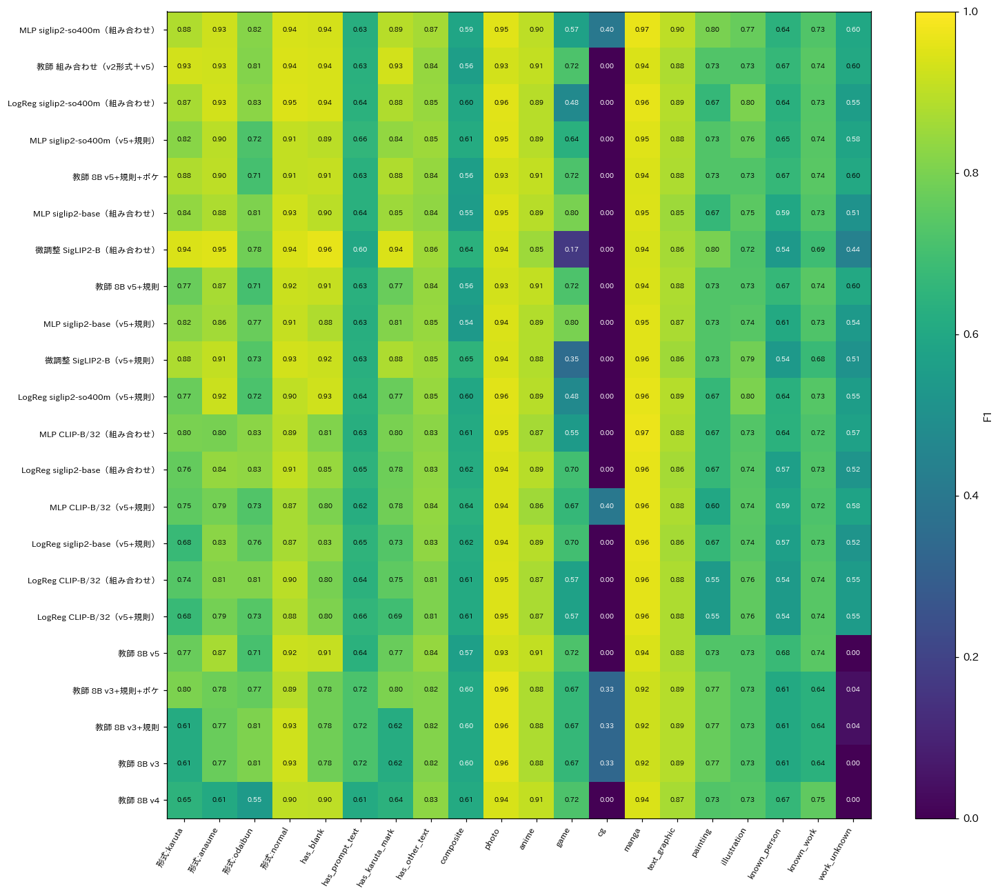

In [22]:
def plot_items4(df: pd.DataFrame, path: str) -> None:
    """主な手法の項目ごとの F1 をヒートマップで描く．

    Args:
        df (pd.DataFrame): agg4 の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    rows, names = [], []
    for _, r in df.iterrows():
        d = runs4[(runs4["method"] == r["method"]) & (runs4["setting"] == r["setting"])].sort_values("seed").iloc[0]
        m = json.load(open(os.path.join(d["run_dir"], "metrics.json")))["eval"]
        vals, cols = [], []
        for c, v in m["format_per_class"].items():
            vals.append(v["f1"]); cols.append(f"形式:{c}")
        for a in ["attr", "media", "know"]:
            for c, v in m[f"{a}_per_item"].items():
                vals.append(v["f1"]); cols.append(c)
        rows.append(vals); names.append(r["label"])
    mat = np.array(rows)
    fig, ax = plt.subplots(figsize=(14, 0.45 * len(names) + 2))
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(cols)), cols, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(names)), names, fontsize=8)
    for i, j in np.ndindex(mat.shape):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=6.5, color="white" if mat[i, j] < 0.6 else "black")
    fig.colorbar(im, ax=ax, label="F1")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_items4(agg4, os.path.join(FIG4, "fig_items_f1.png"))

## 処理速度と精度\n\n横軸は全件（682万枚）の処理時間の見積もり（対数軸），縦軸は4軸のマクロ F1 の平均である．

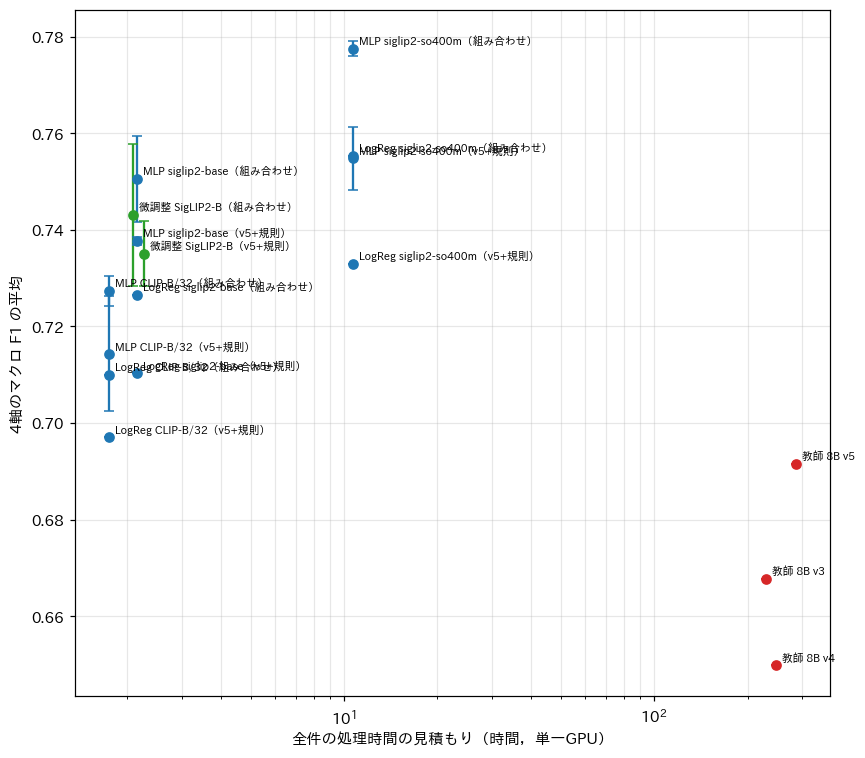

In [23]:
def plot_speed4(df: pd.DataFrame, path: str) -> None:
    """処理時間と4軸のマクロ F1 の平均の散布図を描く．

    Args:
        df (pd.DataFrame): agg4 の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    d = df[df["hours_all"].notna()]
    fig, ax = plt.subplots(figsize=(8, 7))
    for _, r in d.iterrows():
        c = "#d62728" if r["method"].startswith("teacher") else ("#2ca02c" if r["method"].startswith("finetune") else "#1f77b4")
        ax.errorbar(r["hours_all"], r["eval_overall_macro_f1_mean"], yerr=r["eval_overall_macro_f1_std"] if r["n_seeds"] > 1 else 0,
                    fmt="o", color=c, capsize=3)
        ax.annotate(r["label"], (r["hours_all"], r["eval_overall_macro_f1_mean"]), fontsize=7, xytext=(4, 3), textcoords="offset points")
    ax.set_xscale("log")
    ax.set_xlabel("全件の処理時間の見積もり（時間，単一GPU）")
    ax.set_ylabel("4軸のマクロ F1 の平均")
    ax.grid(alpha=0.3, which="both")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_speed4(agg4, os.path.join(FIG4, "fig_speed.png"))

## 微調整の学習曲線\n\n横軸はエポック（0は学習前），左は誤差，右は検証用（教師ラベル）の4軸のマクロ F1 の平均である．塗りつぶしは seed 間の標準偏差．

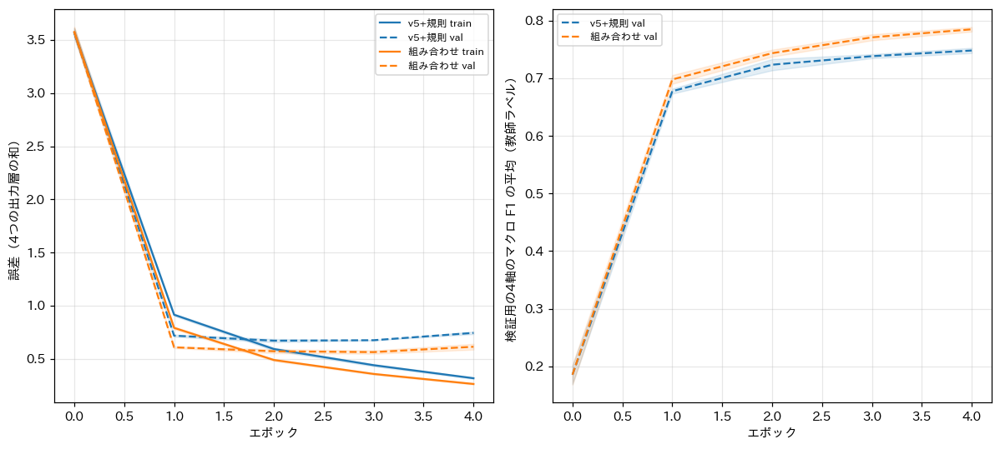

In [24]:
def plot_ft4(path: str) -> None:
    """微調整の log.json から誤差と検証用のマクロ F1 の推移を描く．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    groups = {}
    for p in glob.glob(os.path.join(EX4_DIR, "finetune_*", "*", "*", "log.json")):
        groups.setdefault(p.split(os.sep)[-3], []).append(json.load(open(p)))
    if not groups:
        return
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    for (g, logs), color in zip(sorted(groups.items()), ["#1f77b4", "#ff7f0e"]):
        name = "組み合わせ" if g.startswith("hybrid") else "v5+規則"
        for split, ls in [("train", "-"), ("val", "--")]:
            a = np.array([l[f"{split}_loss"] for l in logs]); x = np.arange(a.shape[1])
            axes[0].plot(x, a.mean(0), ls, color=color, label=f"{name} {split}")
            axes[0].fill_between(x, a.mean(0) - a.std(0), a.mean(0) + a.std(0), color=color, alpha=0.12)
        a = np.array([l["val_overall_macro_f1"] for l in logs]); x = np.arange(a.shape[1])
        axes[1].plot(x, a.mean(0), "--", color=color, label=f"{name} val")
        axes[1].fill_between(x, a.mean(0) - a.std(0), a.mean(0) + a.std(0), color=color, alpha=0.12)
    axes[0].set_ylabel("誤差（4つの出力層の和）")
    axes[1].set_ylabel("検証用の4軸のマクロ F1 の平均（教師ラベル）")
    for ax in axes:
        ax.set_xlabel("エポック")
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_ft4(os.path.join(FIG4, "fig_finetune_curve.png"))

# ex005：定義書 v2（3軸），プロンプトの比較，少ない区分の追加と重み付き損失

評価用データ640枚を調整用（dev，320枚）と最終評価用（test，320枚）に分け，プロンプトは dev で選び，test で評価した．
指標は3軸（形式，属性，媒体）のマクロ F1 の平均（overall）と，正例が10件以上の項目のみの平均（robust）である．

In [25]:
EX5_DIR = os.path.join(OUTPUT_ROOT, "ex005_rare_weighted_distill")
FIG5 = os.path.join(EX5_DIR, "figures")
os.makedirs(FIG5, exist_ok=True)


def load_runs5() -> pd.DataFrame:
    """ex005 の全実行の指標を1行1実行の表に読み込む．

    Returns:
        pd.DataFrame: 列 method, setting, seed と，dev・test・all の指標，処理速度を持つ表．
    """
    rows = []
    for path in glob.glob(os.path.join(EX5_DIR, "*", "*", "*", "metrics.json")):
        seed_dir = os.path.dirname(path)
        m = json.load(open(path))
        meta = json.load(open(os.path.join(seed_dir, "meta.json")))
        r = {"method": seed_dir.split(os.sep)[-3], "setting": seed_dir.split(os.sep)[-2], "seed": seed_dir.split(os.sep)[-1]}
        for part in ["all", "dev", "test"]:
            for k, v in m[part].items():
                if not isinstance(v, dict):
                    r[f"{part}_{k}"] = v
            for axis in ["attr", "media"]:
                for c, v in m[part][f"{axis}_per_item"].items():
                    r[f"{part}_f1_{c}"] = v["f1"]
            for c, v in m[part]["format_per_class"].items():
                r[f"{part}_f1_format_{c}"] = v["f1"]
        r["images_per_sec"] = (meta.get("throughput") or {}).get("images_per_sec")
        rows.append(r)
    return pd.DataFrame(rows)


runs5 = load_runs5()
num5 = [c for c in runs5.columns if c.startswith(("all_", "dev_", "test_")) or c == "images_per_sec"]
agg5 = runs5.groupby(["method", "setting"])[num5].agg(["mean", "std"])
agg5.columns = [f"{a}_{b}" for a, b in agg5.columns]
agg5 = agg5.reset_index()
agg5["n_seeds"] = runs5.groupby(["method", "setting"]).size().values
agg5.to_csv(os.path.join(FIG5, "summary_all.csv"), index=False)
teach5 = agg5[agg5["method"].str.startswith("teacher_") & (agg5["setting"] == "rules")].copy()
teach5["name"] = teach5["method"].str.replace("teacher_", "")
teach5 = teach5.sort_values("dev_overall_robust_f1_mean")
teach5[["name", "dev_format_accuracy_mean", "dev_attr_macro_f1_mean", "dev_media_macro_f1_mean", "dev_overall_macro_f1_mean",
        "dev_overall_robust_f1_mean", "test_overall_macro_f1_mean", "test_overall_robust_f1_mean"]].round(3)

,name,dev_format_accuracy_mean,dev_attr_macro_f1_mean,dev_media_macro_f1_mean,dev_overall_macro_f1_mean,dev_overall_robust_f1_mean,test_overall_macro_f1_mean,test_overall_robust_f1_mean
60,v8_F8b,0.412,0.705,0.773,0.678,0.718,0.700,0.708
59,v8_F8,0.488,0.709,0.773,0.699,0.740,0.710,0.718
44,T_v6cot_joint,0.828,0.780,0.697,0.757,0.819,0.754,0.774
42,T_v6_sep,0.894,0.734,0.773,0.791,0.831,0.814,0.822
48,T_vote3_sep,0.897,0.735,0.773,0.792,0.833,0.816,0.824
40,T_v6_joint,0.894,0.772,0.697,0.778,0.840,0.800,0.821
46,T_v6hr_joint,0.900,0.777,0.697,0.783,0.845,0.798,0.818
61,v8_F8c,0.881,0.787,0.773,0.811,0.852,0.812,0.820
20,T_joint,0.925,0.788,0.697,0.793,0.854,0.790,0.810
76,v8_TLja_fmt,0.919,0.779,0.773,0.818,0.859,0.821,0.828


## 教師の構成の比較（dev と test）

横軸は dev の頑健な指標，縦軸は test の頑健な指標である．破線は y = x．dev での選択が test でも良い構成を選べているかを確かめる．

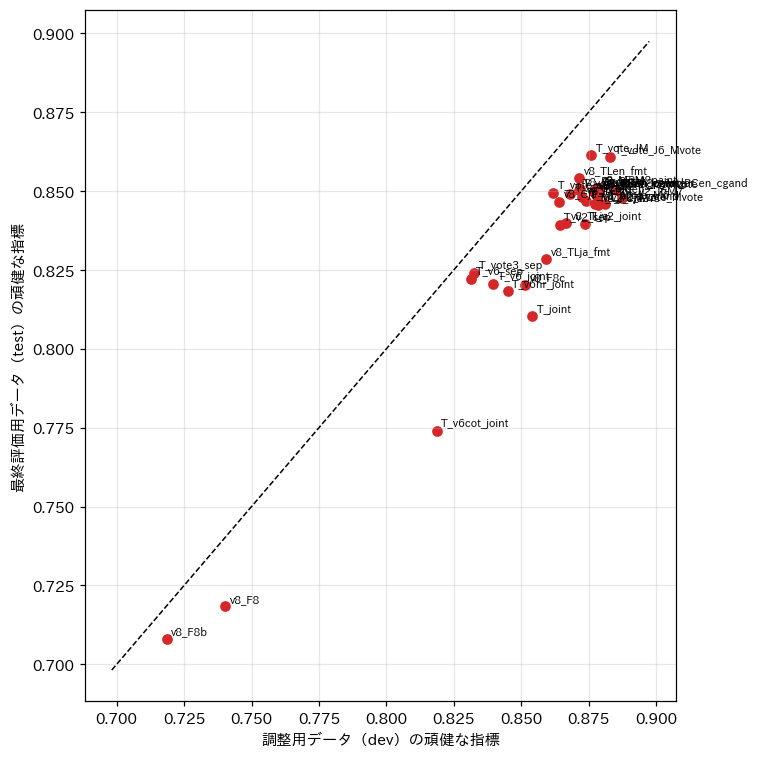

In [26]:
def plot_teacher5(df: pd.DataFrame, path: str) -> None:
    """教師の構成ごとの dev と test の頑健な指標の散布図を描く．

    Args:
        df (pd.DataFrame): teach5 の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    fig, ax = plt.subplots(figsize=(7, 7))
    ax.scatter(df["dev_overall_robust_f1_mean"], df["test_overall_robust_f1_mean"], color="#d62728")
    for _, r in df.iterrows():
        ax.annotate(r["name"], (r["dev_overall_robust_f1_mean"], r["test_overall_robust_f1_mean"]), fontsize=7,
                    xytext=(3, 3), textcoords="offset points")
    lo = min(df["dev_overall_robust_f1_mean"].min(), df["test_overall_robust_f1_mean"].min()) - 0.01
    hi = max(df["dev_overall_robust_f1_mean"].max(), df["test_overall_robust_f1_mean"].max()) + 0.01
    ax.plot([lo, hi], [lo, hi], "k--", lw=1)
    ax.set_xlabel("調整用データ（dev）の頑健な指標")
    ax.set_ylabel("最終評価用データ（test）の頑健な指標")
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_teacher5(teach5, os.path.join(FIG5, "fig_teachers_dev_test.png"))

## 生徒の比較（少ない区分の追加と重み付き損失）

横軸は test の各指標，誤差棒は seed 間の標準偏差である．

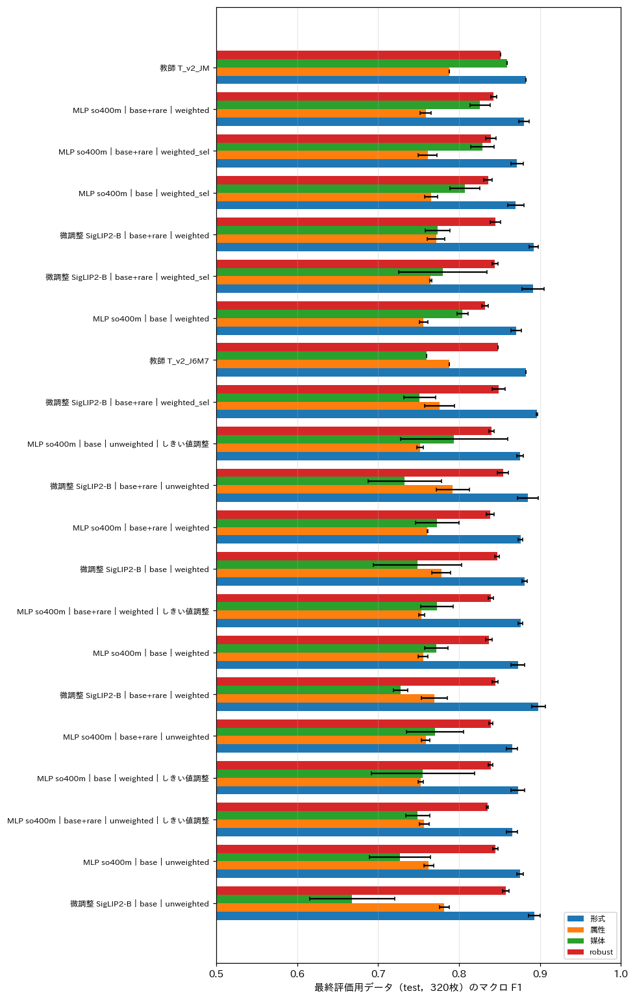

,name,n_seeds,test_format_accuracy_mean,test_format_macro_f1_mean,test_attr_macro_f1_mean,test_media_macro_f1_mean,test_overall_macro_f1_mean,test_overall_macro_f1_std,test_overall_robust_f1_mean,all_overall_macro_f1_mean
0,微調整 SigLIP2-B｜base+rare｜unweighted,3,0.905,0.885,0.792,0.733,0.803,0.017,0.854,0.806
1,微調整 SigLIP2-B｜base+rare｜weighted,3,0.915,0.892,0.772,0.774,0.812,0.009,0.845,0.812
2,微調整 SigLIP2-B｜base+rare｜weighted_sel,3,0.916,0.891,0.765,0.780,0.812,0.015,0.844,0.808
3,微調整 SigLIP2-B｜base｜unweighted,3,0.914,0.893,0.782,0.668,0.781,0.019,0.857,0.791
4,微調整 SigLIP2-B｜base｜weighted,3,0.904,0.881,0.778,0.749,0.803,0.018,0.847,0.805
5,微調整 SigLIP2-B｜base+rare｜weighted,3,0.914,0.898,0.769,0.728,0.798,0.006,0.845,0.813
6,微調整 SigLIP2-B｜base+rare｜weighted_sel,3,0.920,0.896,0.776,0.751,0.808,0.012,0.849,0.821
7,MLP so400m｜base+rare｜unweighted,3,0.897,0.866,0.759,0.771,0.798,0.010,0.839,0.814
8,MLP so400m｜base+rare｜unweighted｜しきい値調整,3,0.897,0.866,0.757,0.749,0.790,0.006,0.835,0.804
9,MLP so400m｜base+rare｜weighted,3,0.899,0.876,0.761,0.773,0.803,0.009,0.838,0.814


In [27]:
stud5 = agg5[agg5["method"].isin(["student_mlp", "finetune_siglip2_base"])].copy()
stud5["name"] = stud5["method"].replace({"student_mlp": "MLP so400m", "finetune_siglip2_base": "微調整 SigLIP2-B"}) + \
    "｜" + stud5["setting"].str.split("__").str[1] + "｜" + stud5["setting"].str.split("__").str[2] +     np.where(stud5["setting"].str.endswith("__thr"), "｜しきい値調整", "")
ref5 = teach5[teach5["name"].isin(["T_v2_J6M7", "T_v2_JM"])].assign(name=lambda x: "教師 " + x["name"])
both5 = pd.concat([stud5, ref5])


def plot_students5(df: pd.DataFrame, path: str) -> None:
    """生徒と教師の test の指標を横棒グラフで描く．

    Args:
        df (pd.DataFrame): 生徒と教師の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    df = df.sort_values("test_overall_macro_f1_mean")
    y = np.arange(len(df))
    keys = [("test_format_macro_f1", "形式"), ("test_attr_macro_f1", "属性"), ("test_media_macro_f1", "媒体"),
            ("test_overall_robust_f1", "robust")]
    fig, ax = plt.subplots(figsize=(9, 0.6 * len(df) + 1.5))
    for i, (k, n) in enumerate(keys):
        ax.barh(y + (i - 1.5) * 0.2, df[f"{k}_mean"], 0.2, xerr=df[f"{k}_std"].fillna(0), capsize=2, label=n)
    ax.set_yticks(y, df["name"], fontsize=8)
    ax.set_xlim(0.5, 1.0)
    ax.set_xlabel("最終評価用データ（test，320枚）のマクロ F1")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(axis="x", alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_students5(both5, os.path.join(FIG5, "fig_students.png"))
both5[["name", "n_seeds", "test_format_accuracy_mean", "test_format_macro_f1_mean", "test_attr_macro_f1_mean",
       "test_media_macro_f1_mean", "test_overall_macro_f1_mean", "test_overall_macro_f1_std", "test_overall_robust_f1_mean",
       "all_overall_macro_f1_mean"]].round(3)

## 少ない区分の項目ごとの F1

行は手法，列は少ない区分（カルタ，ゲーム，CG，絵画）と主な項目である．値は評価用データ全体（640枚）での seed 間の平均である．

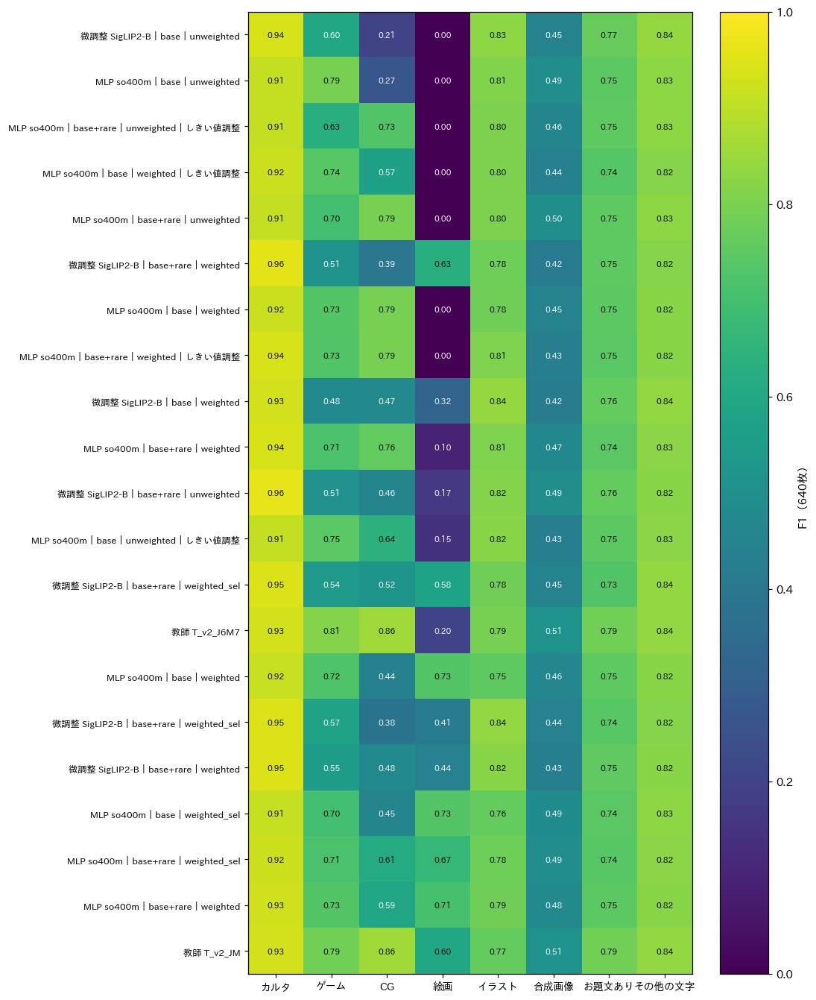

In [28]:
def plot_rare5(df: pd.DataFrame, path: str) -> None:
    """少ない区分と主な項目の F1 をヒートマップで描く．

    Args:
        df (pd.DataFrame): 生徒と教師の表．
        path (str): 保存先のパス．

    Returns:
        None
    """
    cols = ["all_f1_format_karuta_mean", "all_f1_game_mean", "all_f1_cg_mean", "all_f1_painting_mean",
            "all_f1_illustration_mean", "all_f1_composite_mean", "all_f1_has_prompt_text_mean", "all_f1_has_other_text_mean"]
    names = ["カルタ", "ゲーム", "CG", "絵画", "イラスト", "合成画像", "お題文あり", "その他の文字"]
    mat = df[cols].values.astype(float)
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(df) + 1.8))
    im = ax.imshow(mat, vmin=0, vmax=1, cmap="viridis", aspect="auto")
    ax.set_xticks(range(len(names)), names, fontsize=9)
    ax.set_yticks(range(len(df)), df["name"], fontsize=8)
    for i, j in np.ndindex(mat.shape):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if mat[i, j] < 0.6 else "black")
    fig.colorbar(im, ax=ax, label="F1（640枚）")
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_rare5(both5.sort_values("test_overall_macro_f1_mean"), os.path.join(FIG5, "fig_rare_f1.png"))

## 少ない区分の収集の経過

横軸は収集の回，縦軸は Qwen がその区分と判定した画像の累積の枚数である．破線は目標の N = 1,000．

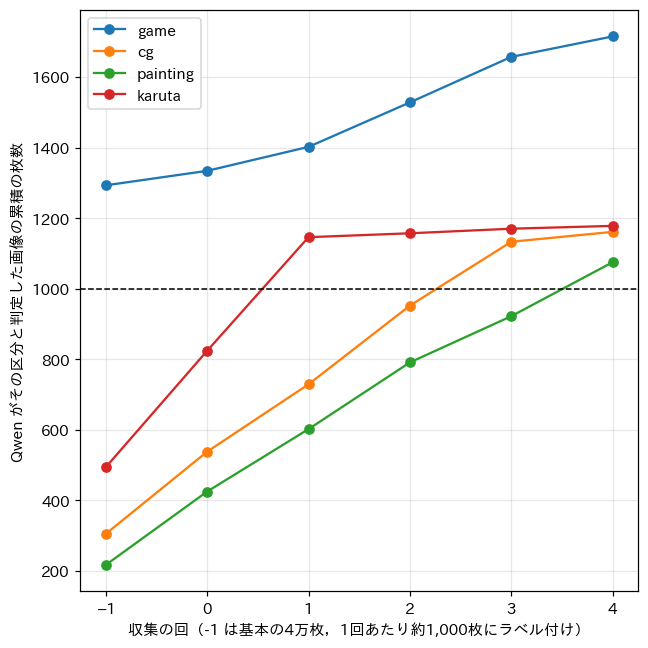

In [29]:
def plot_mining(path: str) -> None:
    """mining_log.json から少ない区分の累積の枚数の推移を描く．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    p = os.path.join(PROJECT_DIR, "datasets", "ex005_rare_weighted_distill", "mining_log.json")
    if not os.path.exists(p):
        return
    obj = json.load(open(p))
    base, log = obj["base_count"], obj["rounds"]
    fig, ax = plt.subplots(figsize=(6, 6))
    for c in base:
        ax.plot([-1] + [r["round"] for r in log], [base[c]] + [r["confirmed"][c] for r in log], marker="o", label=c)
    ax.axhline(1000, ls="--", color="k", lw=1)
    ax.set_xlabel("収集の回（-1 は基本の4万枚，1回あたり約1,000枚にラベル付け）")
    ax.set_ylabel("Qwen がその区分と判定した画像の累積の枚数")
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_mining(os.path.join(FIG5, "fig_mining.png"))

## 少ない区分の評価用データ（200枚）での F1

横軸は少ない区分（ゲーム，CG，絵画，カルタ）と，その平均（rare macro）である．縦の誤差棒は seed 間の標準偏差．教師の値は破線で示す．

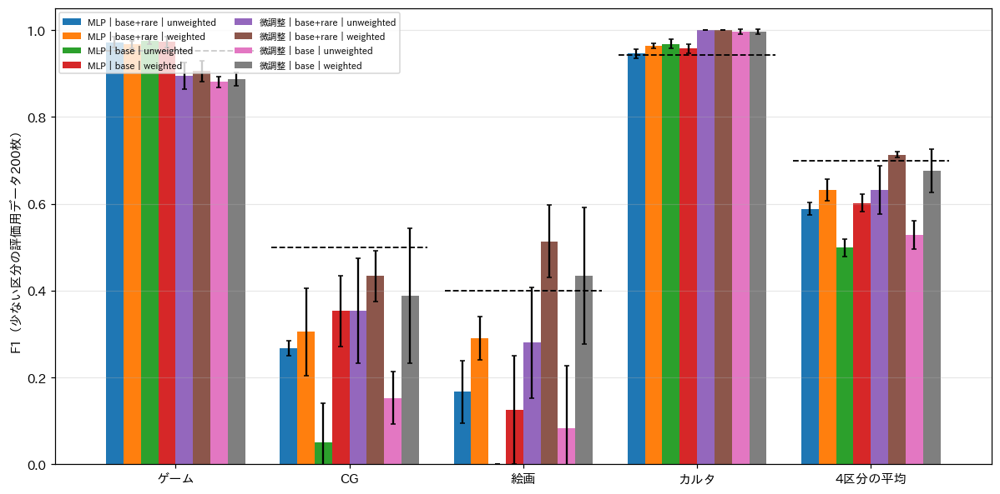

In [30]:
def plot_rare_eval(path: str) -> None:
    """少ない区分の評価用データでの生徒（条件ごと）と教師の F1 を描く．

    Args:
        path (str): 保存先のパス．

    Returns:
        None
    """
    d = pd.read_csv(os.path.join(FIG5, "rare_eval_all.csv"))
    t = pd.read_csv(os.path.join(FIG5, "rare_eval_teachers.csv"))
    cls = ["game", "cg", "painting", "karuta"]
    d = d[~d["setting"].str.endswith("__thr")]
    d["cond"] = d["method"].replace({"student_mlp": "MLP", "finetune_siglip2_base": "微調整"}) + "｜" +         d["setting"].str.split("__").str[1] + "｜" + d["setting"].str.split("__").str[2]
    g = d.groupby("cond")[[f"{c}_f1" for c in cls] + ["macro_f1"]].agg(["mean", "std"])
    order = sorted(g.index, key=lambda x: (x.split("｜")[0], x))
    fig, ax = plt.subplots(figsize=(11, 5.5))
    xs = np.arange(len(cls) + 1)
    w = 0.8 / len(order)
    for i, cnd in enumerate(order):
        m = [g.loc[cnd, (f"{c}_f1", "mean")] for c in cls] + [g.loc[cnd, ("macro_f1", "mean")]]
        e = [g.loc[cnd, (f"{c}_f1", "std")] for c in cls] + [g.loc[cnd, ("macro_f1", "std")]]
        ax.bar(xs - 0.4 + w * (i + 0.5), m, w, yerr=e, capsize=2, label=cnd)
    tr = t[t["teacher"] == "T_v2_J6M7"].iloc[0]
    for x, v in zip(xs, [tr[f"{c}_f1"] for c in cls] + [tr["macro_f1"]]):
        ax.hlines(v, x - 0.45, x + 0.45, colors="k", linestyles="--", lw=1.2)
    ax.set_xticks(xs, ["ゲーム", "CG", "絵画", "カルタ", "4区分の平均"])
    ax.set_ylabel("F1（少ない区分の評価用データ200枚）")
    ax.set_ylim(0, 1.05)
    ax.legend(fontsize=7, ncol=2, loc="upper left")
    ax.grid(axis="y", alpha=0.3)
    fig.tight_layout()
    fig.savefig(path, bbox_inches="tight")
    plt.show()


plot_rare_eval(os.path.join(FIG5, "fig_rare_eval.png"))

# ex005（order_009）：プロンプトの改善策と少ない区分の評価用データの拡充

`programs/ex005_rare_weighted_distill/figures_v8.py` で図を作り，表示する．教師の構成は調整用データ（dev），
生徒は最終評価用データ（test）で比較する．

shape: (11, 5)
┌──────────────────────────┬───────────────────┬──────────────────┬────────────────┬───────────────┐
│ name                     ┆ test_overall_mean ┆ test_robust_mean ┆ rare_test_mean ┆ rare_test_std │
│ ---                      ┆ ---               ┆ ---              ┆ ---            ┆ ---           │
│ str                      ┆ f64               ┆ f64              ┆ f64            ┆ f64           │
╞══════════════════════════╪═══════════════════╪══════════════════╪════════════════╪═══════════════╡
│ 微調整｜T_v2_J6M7｜base  ┆ 0.780873          ┆ 0.857441         ┆ 0.509726       ┆ 0.015445      │
│ ｜unweighted             ┆                   ┆                  ┆                ┆               │
│ 微調整｜T_v2_J6M7｜base+ ┆ 0.80344           ┆ 0.85418          ┆ 0.550654       ┆ 0.057217      │
│ rare｜unweig…            ┆                   ┆                  ┆                ┆               │
│ 微調整｜T_v2_J6M7｜base  ┆ 0.802609          ┆ 0.846929         ┆ 0.647961       ┆ 0.054561

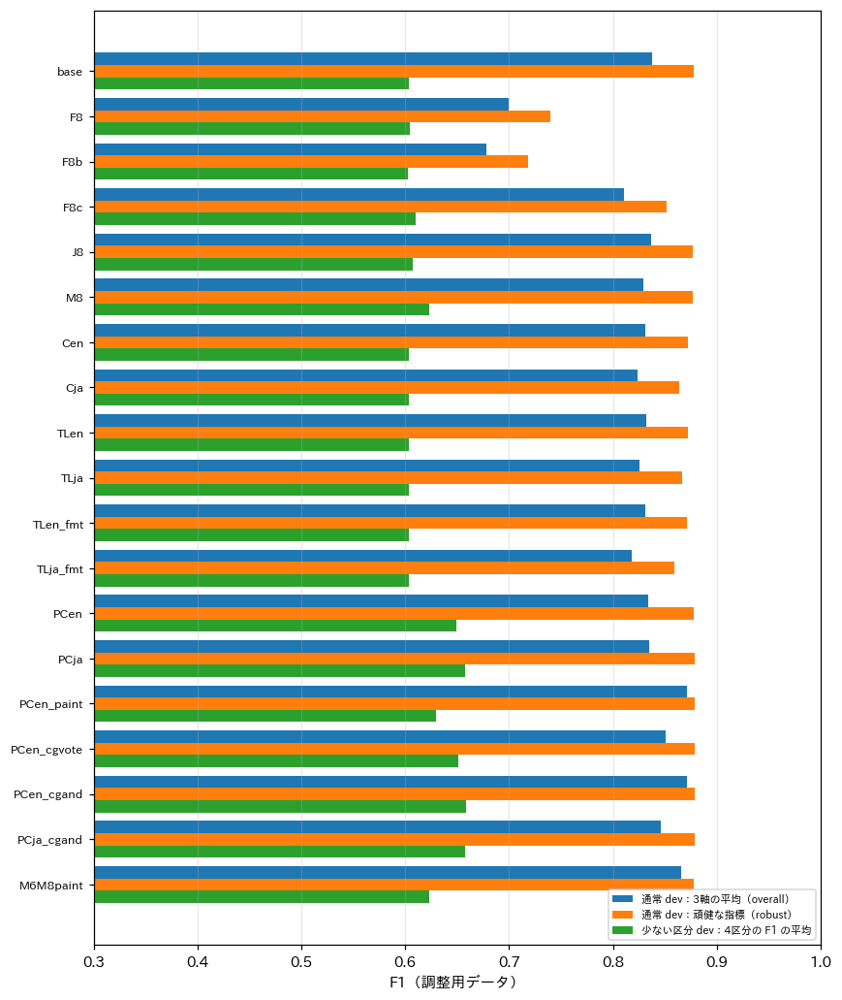

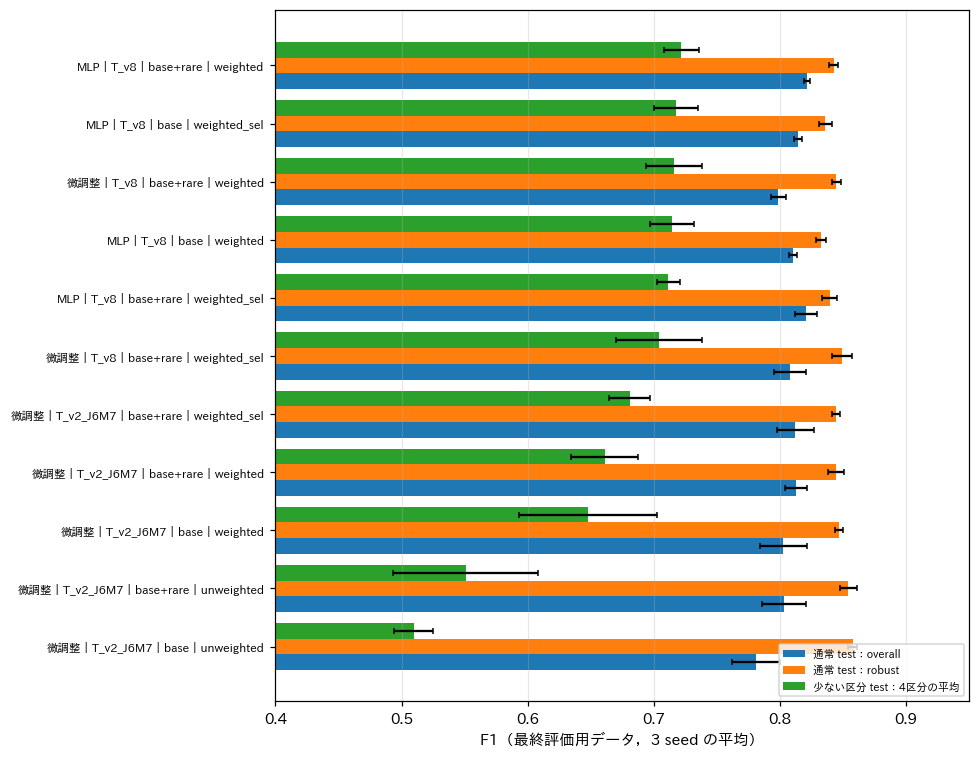

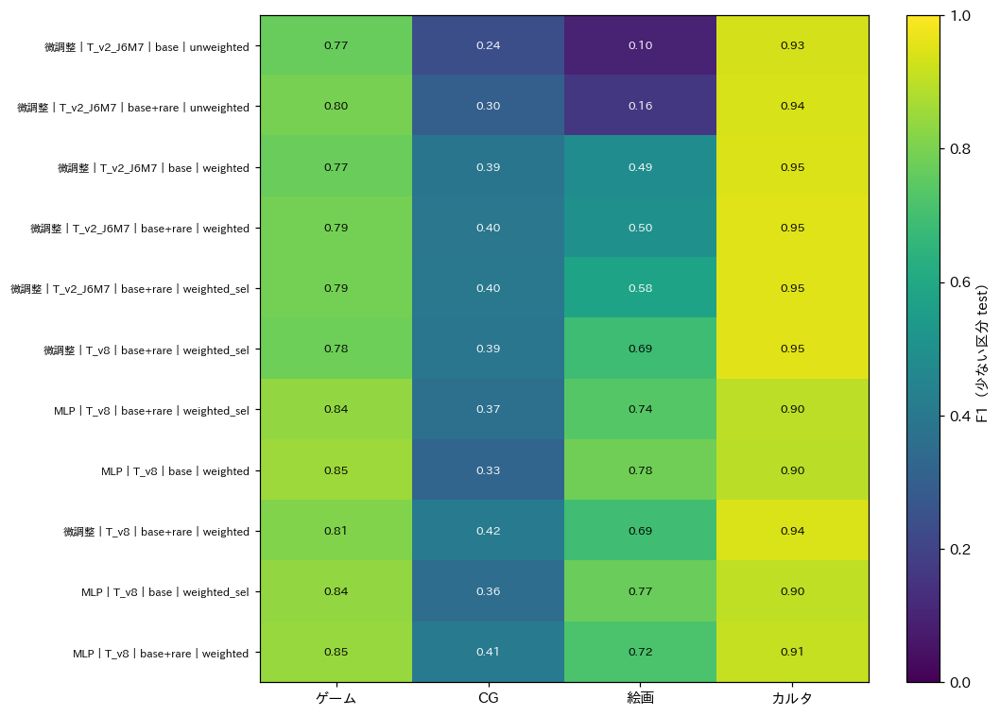

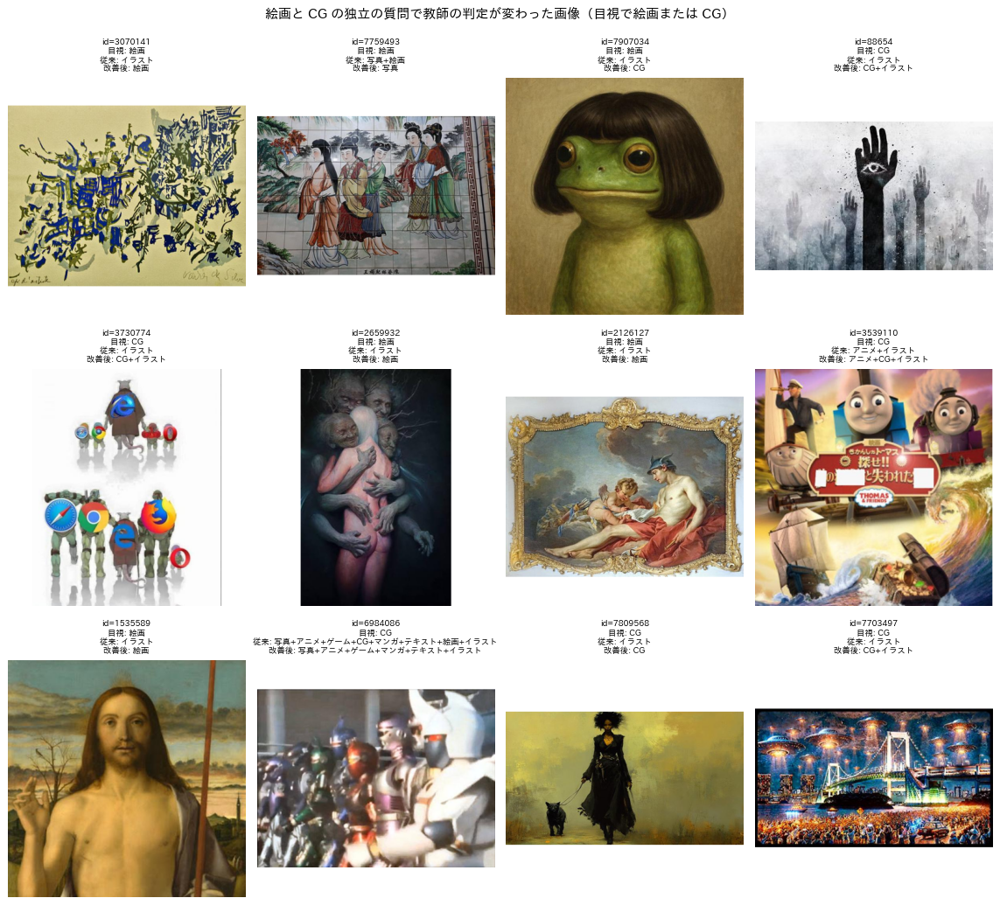

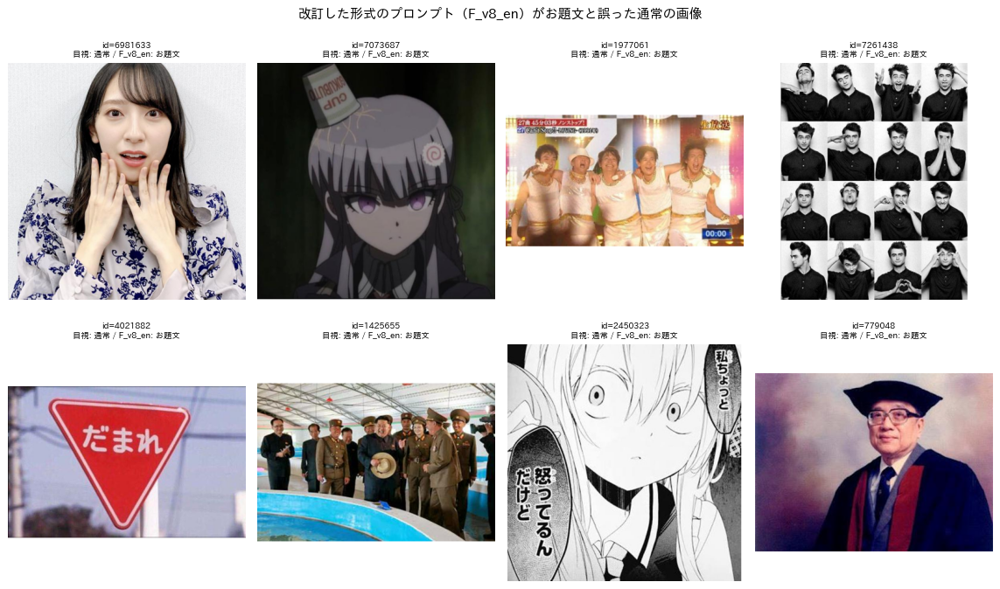

,name,test_overall_mean,test_robust_mean,rare_test_mean,rare_game_mean,rare_cg_mean,rare_painting_mean,rare_karuta_mean,test_overall_std,test_robust_std,rare_test_std,rare_game_std,rare_cg_std,rare_painting_std,rare_karuta_std
0,微調整｜T_v2_J6M7｜base｜unweighted,0.781,0.857,0.510,0.769,0.239,0.097,0.934,0.019,0.004,0.015,0.005,0.096,0.095,0.003
1,微調整｜T_v2_J6M7｜base+rare｜unweighted,0.803,0.854,0.551,0.796,0.304,0.162,0.940,0.017,0.007,0.057,0.041,0.152,0.071,0.016
2,微調整｜T_v2_J6M7｜base｜weighted,0.803,0.847,0.648,0.770,0.388,0.488,0.946,0.018,0.003,0.055,0.032,0.035,0.264,0.013
3,微調整｜T_v2_J6M7｜base+rare｜weighted,0.812,0.845,0.661,0.792,0.398,0.504,0.950,0.009,0.006,0.027,0.019,0.071,0.006,0.016
4,微調整｜T_v2_J6M7｜base+rare｜weighted_sel,0.812,0.844,0.681,0.793,0.400,0.580,0.951,0.015,0.003,0.017,0.026,0.052,0.100,0.013
5,微調整｜T_v8｜base+rare｜weighted_sel,0.808,0.849,0.704,0.778,0.395,0.690,0.954,0.012,0.008,0.034,0.041,0.076,0.041,0.014
6,MLP｜T_v8｜base+rare｜weighted_sel,0.821,0.839,0.712,0.838,0.370,0.738,0.900,0.009,0.006,0.009,0.011,0.051,0.037,0.012
7,MLP｜T_v8｜base｜weighted,0.810,0.832,0.715,0.853,0.327,0.782,0.897,0.003,0.004,0.017,0.003,0.108,0.037,0.015
8,微調整｜T_v8｜base+rare｜weighted,0.798,0.845,0.716,0.812,0.417,0.693,0.942,0.006,0.003,0.022,0.034,0.026,0.074,0.003
9,MLP｜T_v8｜base｜weighted_sel,0.814,0.836,0.717,0.839,0.358,0.770,0.903,0.003,0.005,0.018,0.014,0.049,0.037,0.005


In [31]:
import subprocess
from IPython.display import Image, display

subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "programs", "ex005_rare_weighted_distill", "figures_v8.py")], check=True)
for name in ["fig_v8_teachers.png", "fig_v8_students.png", "fig_v8_rare_items.png", "fig_v8_pc_examples.png", "fig_v8_f8_errors.png"]:
    display(Image(os.path.join(OUTPUT_ROOT, "ex005_rare_weighted_distill", "figures", name)))
pd.read_csv(os.path.join(OUTPUT_ROOT, "ex005_rare_weighted_distill", "figures", "summary_v8_students.csv")).round(3)

# ex007（order_011）：定義書 v3 の教師・生徒と実データの無作為抽出による確認

`programs/ex007_label_v3/summarize.py` で集計した教師と生徒の精度と，実データ160枚の目視のラベルに対する生徒（seed 0）の精度を表示する．

shape: (10, 11)
┌────────────┬────────────┬─────┬────────────┬───┬────────────┬────────────┬───────────┬───────────┐
│ method     ┆ setting    ┆ n   ┆ dev_overal ┆ … ┆ test_media ┆ test_overa ┆ test_over ┆ rare_test │
│ ---        ┆ ---        ┆ --- ┆ l_macro_f1 ┆   ┆ _macro_f1  ┆ ll_macro_f ┆ all_robus ┆ ---       │
│ str        ┆ str        ┆ u32 ┆ ---        ┆   ┆ ---        ┆ 1          ┆ t_f1      ┆ f64       │
│            ┆            ┆     ┆ f64        ┆   ┆ f64        ┆ ---        ┆ ---       ┆           │
│            ┆            ┆     ┆            ┆   ┆            ┆ f64        ┆ f64       ┆           │
╞════════════╪═══════════���╪═════╪════════════╪═══╪════════════╪════════════╪═══════════╪═══════════╡
│ teacher_T_ ┆ rules      ┆ 1   ┆ 0.912084   ┆ … ┆ 0.837433   ┆ 0.880481   ┆ 0.892138  ┆ 0.854716  │
│ v9         ┆            ┆     ┆            ┆   ┆            ┆            ┆           ┆           │
│ teacher_T_ ┆ rules      ┆ 1   ┆ 0.911265   ┆ … ┆ 0.85643    ┆ 0.886813 

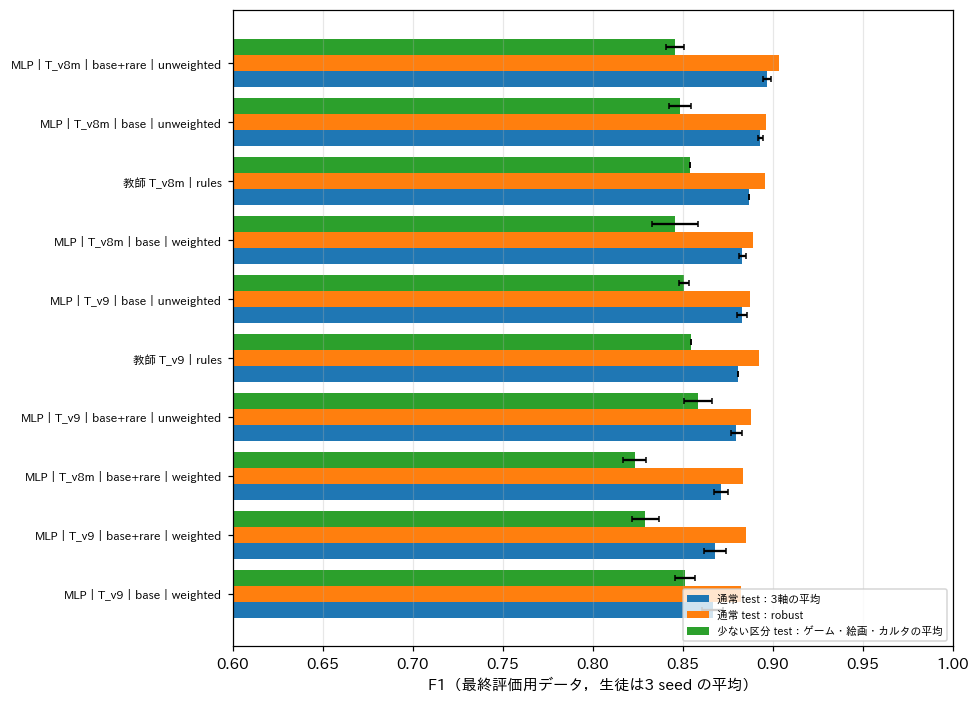

,run,format_accuracy,attr_macro_f1,media_macro_f1,all_correct,media_multi_rate
0,student_mlp/T_v8m__base+rare__unweighted,0.950,0.939,0.922,0.744,0.069
4,student_mlp/T_v9__base+rare__unweighted,0.931,0.930,0.925,0.731,0.058
6,student_mlp/T_v9__base__unweighted,0.944,0.915,0.913,0.719,0.070
2,student_mlp/T_v8m__base__unweighted,0.944,0.938,0.929,0.719,0.064
7,student_mlp/T_v9__base__weighted,0.938,0.919,0.897,0.706,0.083
1,student_mlp/T_v8m__base+rare__weighted,0.925,0.921,0.887,0.688,0.103
3,student_mlp/T_v8m__base__weighted,0.925,0.928,0.879,0.688,0.095
5,student_mlp/T_v9__base+rare__weighted,0.925,0.920,0.894,0.675,0.110


In [32]:
import json

subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "programs", "ex007_label_v3", "summarize.py")], check=True)
display(Image(os.path.join(OUTPUT_ROOT, "ex007_label_v3", "figures", "fig_summary.png")))
rc = json.load(open(os.path.join(OUTPUT_ROOT, "ex007_label_v3", "figures", "real_check.json")))
pd.DataFrame([{"run": k, **{c: v["check"][c] for c in ["format_accuracy", "attr_macro_f1", "media_macro_f1", "all_correct"]},
               "media_multi_rate": v["media_multi_rate"]} for k, v in rc.items() if k.startswith("student")]
             ).sort_values("all_correct", ascending=False).round(3)

# ex008（order_012）：定義書 v4（文字ありにロゴ等を含める），お題文の確認の質問，目視ラベルの追加

`programs/ex008_label_v4/analyze.py` で，教師と生徒を通常の評価用データ，少ない区分の評価用データ，
実データの無作為抽出160枚，層別抽出220枚（重みなし，および抽出確率の逆数で重み付けした推定）で評価した結果を表示する．

shape: (16, 15)
┌─────────────────┬─────┬─────────────────┬─────────────────┬─────────────────┬───────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬─────────────────┬────────────────┬────────────────┬────────────────┐
│ run             ┆ n   ┆ dev_overall_mac ┆ dev_overall_rob ┆ test_overall_ma ┆ rare_test ┆ random_format_a ┆ random_overall_ ┆ random_all_corr ┆ strat_uniform_f ┆ strat_uniform_o ┆ strat_uniform_a ┆ pooled_ipw_for ┆ pooled_ipw_ove ┆ pooled_ipw_all │
│ ---             ┆ --- ┆ ro_f1           ┆ ust_f1          ┆ cro_f1          ┆ ---       ┆ ccuracy         ┆ macro_f1        ┆ ect             ┆ ormat_accuracy  ┆ verall_macro_f1 ┆ ll_correct      ┆ mat_accuracy   ┆ rall_macro_f1  ┆ _correct       │
│ str             ┆ u32 ┆ ---             ┆ ---             ┆ ---             ┆ f64       ┆ ---             ┆ ---             ┆ ---             ┆ ---             ┆ ---             ┆ ---             ┆ ---            ┆ ---           

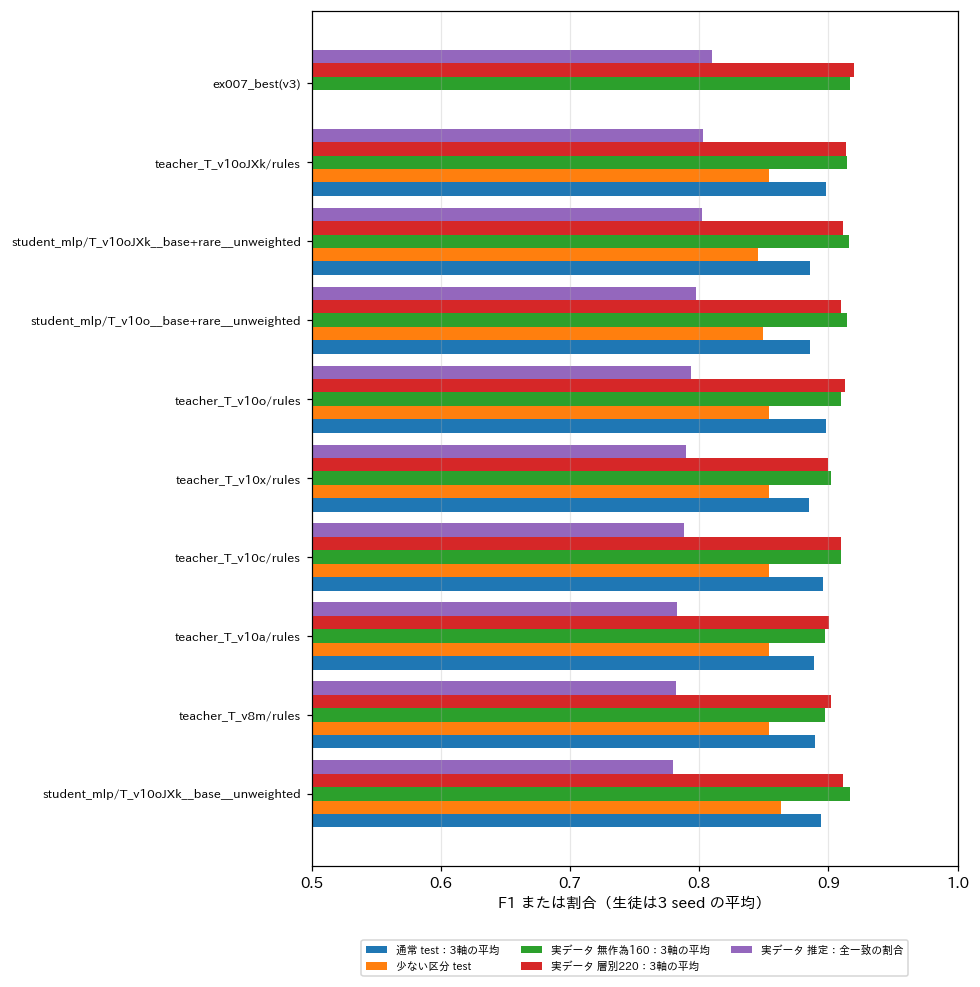

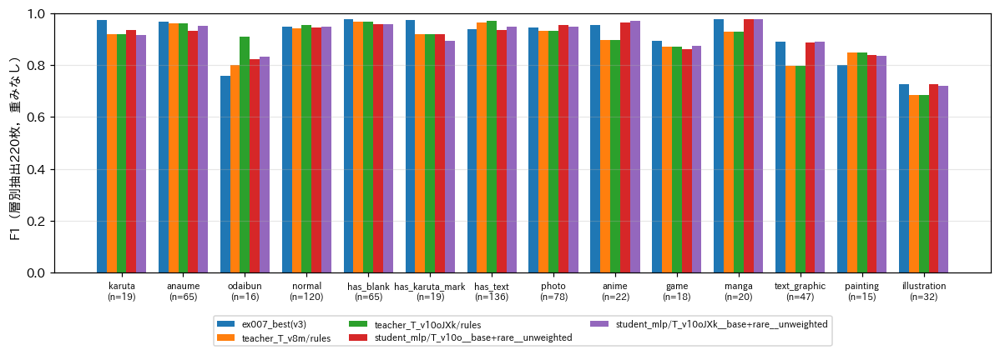

,run,n,dev_format_macro_f1,dev_attr_macro_f1,dev_media_macro_f1,dev_overall_macro_f1,dev_overall_robust_f1,rare_dev,test_format_macro_f1,test_attr_macro_f1,...,strat_uniform_overall_macro_f1,strat_uniform_all_correct,strat_uniform_media_multi_rate,pooled_ipw_format_accuracy,pooled_ipw_format_macro_f1,pooled_ipw_attr_macro_f1,pooled_ipw_media_macro_f1,pooled_ipw_overall_macro_f1,pooled_ipw_all_correct,pooled_ipw_media_multi_rate
0,ex007_best(v3),1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,0.919,0.714,0.105,0.950,0.926,0.967,0.856,0.916,0.810,0.068
1,teacher_T_v10coJXk/rules,1,0.938,0.950,0.857,0.915,0.929,0.754,0.909,0.932,...,0.919,0.718,0.168,0.964,0.950,0.964,0.805,0.906,0.806,0.116
2,teacher_T_v10oJXk/rules,1,0.940,0.952,0.857,0.916,0.930,0.752,0.907,0.930,...,0.913,0.718,0.168,0.957,0.936,0.954,0.805,0.898,0.803,0.116
3,student_mlp/T_v10oJXk__base+rare__unweighted,3,0.946,0.944,0.811,0.900,0.933,0.795,0.869,0.910,...,0.911,0.729,0.089,0.956,0.937,0.936,0.883,0.919,0.802,0.062
4,teacher_T_v10ox/rules,1,0.940,0.941,0.857,0.913,0.927,0.752,0.907,0.919,...,0.910,0.682,0.168,0.957,0.936,0.953,0.805,0.898,0.802,0.116
5,teacher_T_v10oJX/rules,1,0.940,0.941,0.857,0.913,0.927,0.752,0.907,0.917,...,0.910,0.682,0.168,0.957,0.936,0.952,0.805,0.898,0.799,0.116
6,student_mlp/T_v10o__base+rare__unweighted,3,0.948,0.951,0.805,0.902,0.935,0.774,0.880,0.919,...,0.910,0.703,0.100,0.948,0.928,0.951,0.871,0.917,0.797,0.064
7,student_mlp/T_v10o__base__unweighted,3,0.927,0.944,0.799,0.890,0.925,0.752,0.878,0.913,...,0.909,0.700,0.123,0.953,0.935,0.950,0.860,0.915,0.796,0.074
8,teacher_T_v11/rules,1,0.933,0.952,0.857,0.914,0.928,0.752,0.884,0.930,...,0.905,0.709,0.168,0.946,0.919,0.954,0.805,0.893,0.794,0.116
9,teacher_T_v10o/rules,1,0.940,0.959,0.857,0.919,0.933,0.752,0.907,0.931,...,0.913,0.714,0.168,0.957,0.936,0.949,0.805,0.897,0.794,0.116


In [33]:
subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "programs", "ex008_label_v4", "analyze.py")], check=True)
for name in ["fig_summary.png", "fig_strat_items.png"]:
    display(Image(os.path.join(OUTPUT_ROOT, "ex008_label_v4", "figures", name)))
pd.read_csv(os.path.join(OUTPUT_ROOT, "ex008_label_v4", "figures", "summary.csv")).round(3)

# ex009（order_013）：最終版の構成の比較

`programs/ex009_final/compare.py` の集計（生徒のモデルと後処理の組み合わせ）と，最終版の構成の項目ごとの精度
（`figures.py` の final_metrics.json），少量での動作確認のアノテーションの例を表示する．

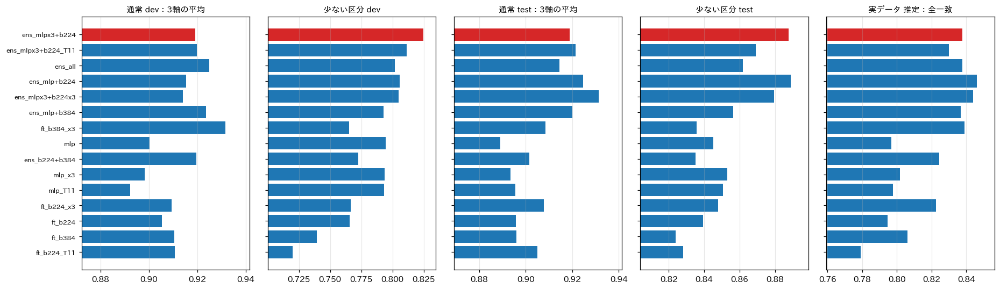

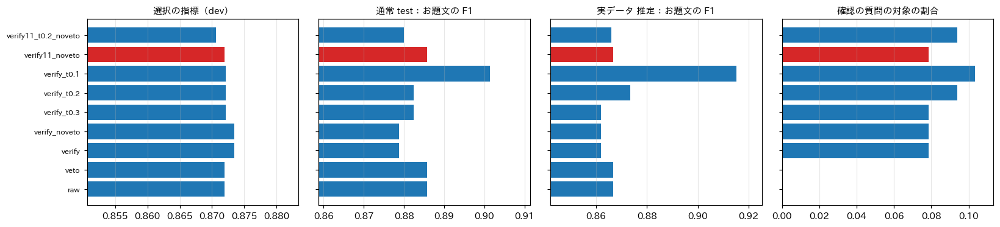

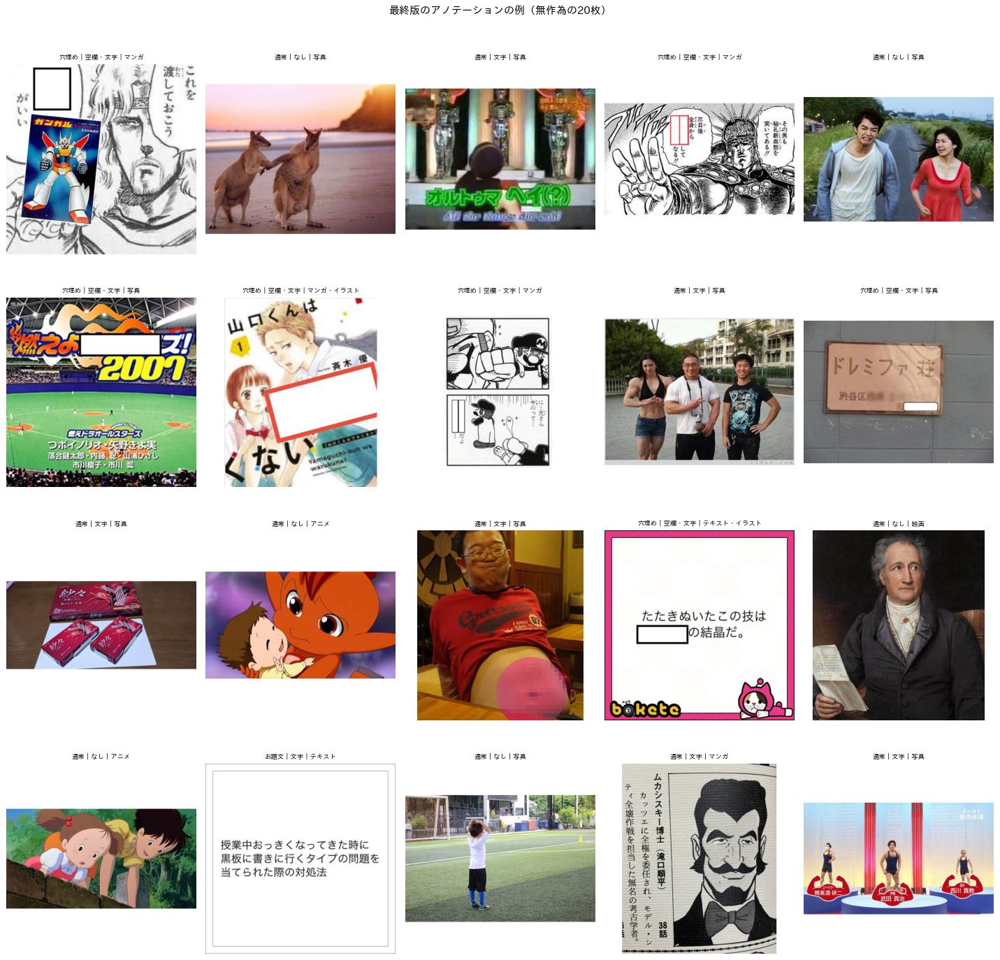

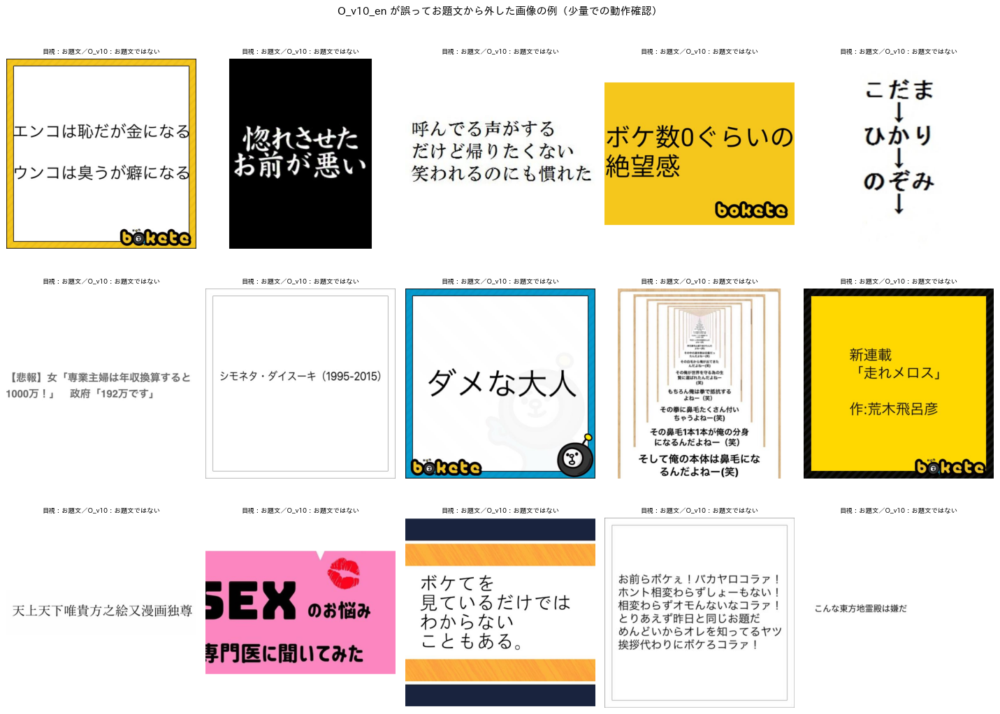

,source,post,n,dev_overall,dev_robust,dev_odaibun,test_overall,test_robust,test_odaibun,rare_dev,...,strat_uniform_overall,strat_uniform_all_correct,strat_uniform_odaibun,pooled_ipw_overall,pooled_ipw_all_correct,pooled_ipw_odaibun,ask_rate,n_vetoed,odaibun_rate_real,select_score
110,ens_mlpx3+b224,verify,1,0.919,0.955,0.943,0.919,0.914,0.879,0.828,...,0.940,0.786,0.848,0.922,0.835,0.862,0.079,1.0,0.073,0.873
111,ens_mlpx3+b224,verify_noveto,1,0.919,0.955,0.943,0.919,0.914,0.879,0.828,...,0.940,0.786,0.848,0.922,0.835,0.862,0.079,0.0,0.073,0.873
112,ens_mlpx3+b224,verify_t0.3,1,0.916,0.952,0.917,0.919,0.914,0.882,0.828,...,0.940,0.786,0.848,0.922,0.835,0.862,0.079,1.0,0.073,0.872
113,ens_mlpx3+b224,verify_t0.2,1,0.916,0.952,0.917,0.919,0.914,0.882,0.828,...,0.944,0.786,0.889,0.923,0.835,0.874,0.094,1.0,0.080,0.872
114,ens_mlpx3+b224,verify_t0.1,1,0.916,0.952,0.917,0.921,0.916,0.901,0.828,...,0.944,0.786,0.889,0.926,0.838,0.915,0.103,1.0,0.086,0.872
109,ens_mlpx3+b224,veto,1,0.919,0.955,0.944,0.919,0.914,0.886,0.825,...,0.941,0.791,0.857,0.922,0.838,0.867,0.000,1.0,0.079,0.872
115,ens_mlpx3+b224,verify11_noveto,1,0.919,0.955,0.944,0.919,0.914,0.886,0.825,...,0.941,0.791,0.857,0.922,0.838,0.867,0.079,0.0,0.079,0.872
108,ens_mlpx3+b224,raw,1,0.919,0.955,0.944,0.919,0.914,0.886,0.825,...,0.941,0.791,0.857,0.922,0.838,0.867,0.000,0.0,0.079,0.872
116,ens_mlpx3+b224,verify11_t0.2_noveto,1,0.917,0.952,0.919,0.918,0.914,0.880,0.825,...,0.945,0.791,0.900,0.922,0.835,0.866,0.094,0.0,0.094,0.871
129,ens_mlpx3+b224_T11,verify_noveto,1,0.921,0.954,0.930,0.925,0.920,0.886,0.811,...,0.938,0.768,0.882,0.918,0.828,0.869,0.095,0.0,0.074,0.866


{'overall': 0.918803046079951,
 'robust': 0.914358289345181,
 'format': {'karuta': 0.8837209302325582,
  'anaume': 0.9349112426035503,
  'odaibun': 0.8857142857142857,
  'normal': 0.9553072625698324},
 'attr': {'has_blank': 0.9371428571428572,
  'has_karuta_mark': 0.8837209302325582,
  'has_text': 0.9702970297029703},
 'media': {'photo': [0.967032967032967, 137],
  'anime': [0.8888888888888888, 32],
  'game': [0.8888888888888888, 5],
  'manga': [0.9056603773584906, 49],
  'text_graphic': [0.9508196721311475, 60],
  'painting': [1.0, 3],
  'illustration': [0.7764705882352941, 47]}}

In [34]:
import json

for name in ["fig_models.png", "fig_posts.png"]:
    display(Image(os.path.join(OUTPUT_ROOT, "ex009_final", "compare", name)))
for name in ["fig_examples.png", "fig_o10_wrong.png"]:
    display(Image(os.path.join(OUTPUT_ROOT, "ex009_final", "figures", name)))
summary = pd.read_csv(os.path.join(OUTPUT_ROOT, "ex009_final", "compare", "summary.csv"))
display(summary.sort_values("select_score", ascending=False).round(3).head(30))
json.load(open(os.path.join(OUTPUT_ROOT, "ex009_final", "figures", "final_metrics.json")))["eval_test"]

# order_014：全データのアノテーションの結果

`Bokete_Annotation_programs_v5.0/outputs/BoketeDBv5_annotation/` の summary.json（ラベルの割合，処理の記録）と，
`scripts/quality_check.py` で作ったラベルごとの無作為の画像の一覧の一部を表示する．

,割合
karuta,0.0109
anaume,0.2007
odaibun,0.0826
normal,0.7059
has_blank,0.2140
has_karuta_mark,0.0110
has_text,0.5856
photo,0.5312
anime,0.0907
game,0.0233


{'n_odai': 6823270, 'n_unique_images': 6609511, 'media_multi_rate': 0.06010593161343462, 'verify_asked_rate': 0.08314854900949252, 'verify_rejected': 3998}


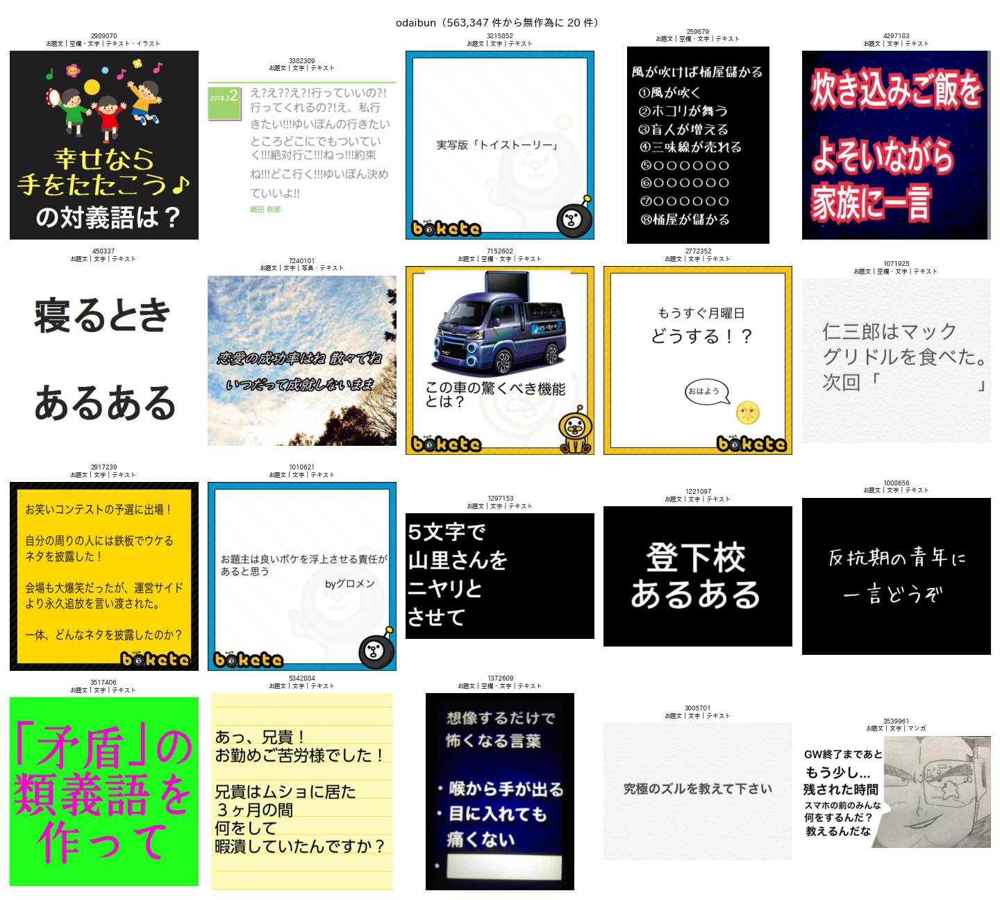

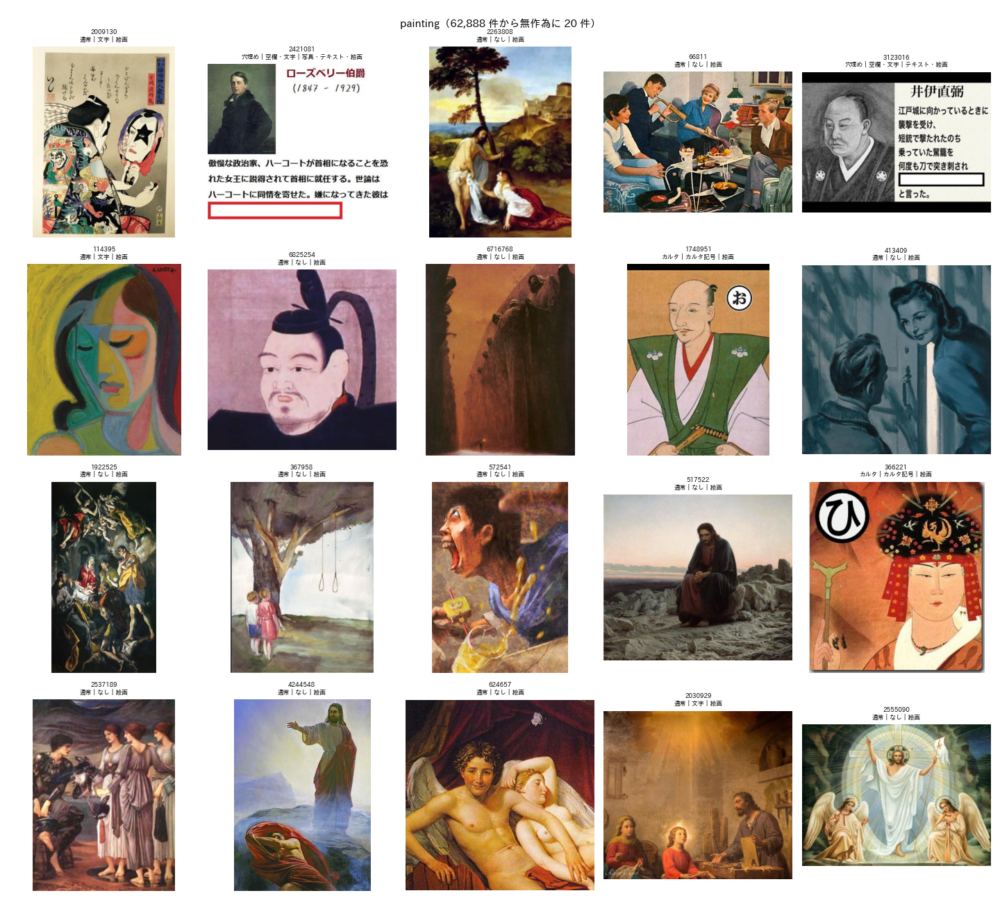

In [35]:
ANN_DIR = os.path.join(PROJECT_DIR, "Bokete_Annotation_programs_v5.0", "outputs", "BoketeDBv5_annotation")
summary = json.load(open(os.path.join(ANN_DIR, "summary.json")))
display(pd.DataFrame({"割合": {**summary["format_rate"], **summary["item_rate"]}}).round(4))
print({k: summary[k] for k in ["n_odai", "n_unique_images", "media_multi_rate", "verify_asked_rate", "verify_rejected"]})
for name in ["odaibun", "painting"]:
    display(Image(os.path.join(ANN_DIR, "quality_check", f"{name}.png")))

# ex010（order_015）：写真のキャプションの生成方法の比較（試作）

`programs/ex010_photo_caption/summarize.py` の集計（方法ごとの速度と，Qwen3-VL-32B の採点）と，目視の採点との一致（manual_check.json）を表示する．

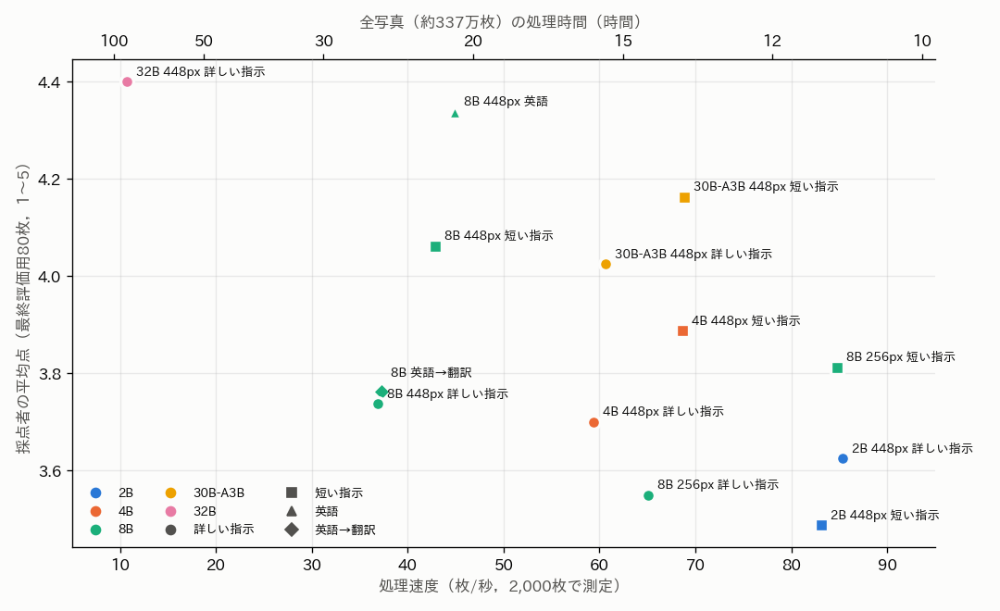

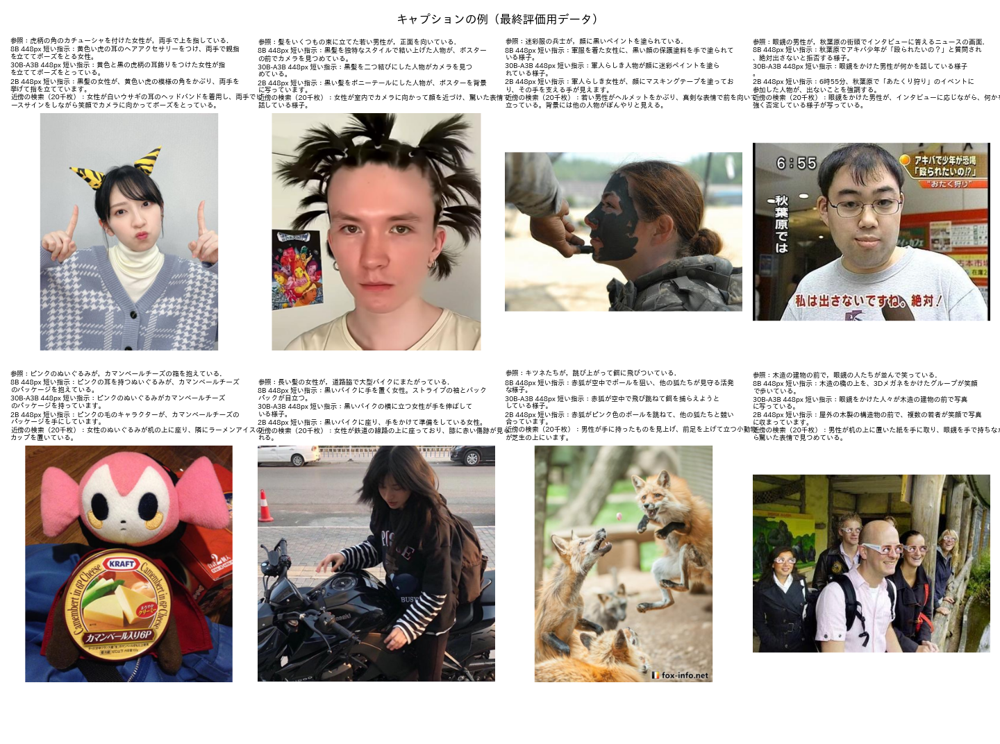

,method,images_per_sec,hours_all_photos,mean_chars,dev_score,dev_ok,dev_halluc,dev_subject,dev_score_se,test_score,test_ok,test_halluc,test_subject,test_score_se
0,reference,NaN,NaN,NaN,5.000,1.000,0.000,1.000,0.000,5.000,1.000,0.000,1.000,0.000
1,q32_448_ja,10.718,87.367,49.333,4.250,0.900,0.100,0.950,0.155,4.400,0.925,0.075,0.950,0.092
2,q8_448_en,44.917,20.848,80.692,4.450,0.900,0.100,1.000,0.138,4.338,0.900,0.100,0.988,0.101
3,q30a3_448_short,68.797,13.611,25.600,3.875,0.850,0.150,0.925,0.153,4.162,0.862,0.125,1.000,0.104
4,q8_448_short,42.855,21.851,30.792,4.150,0.925,0.075,0.950,0.137,4.062,0.838,0.150,0.950,0.114
5,q30a3_448_ja,60.632,15.444,27.967,3.700,0.750,0.225,0.900,0.187,4.025,0.825,0.175,0.975,0.119
6,q4_448_short,68.645,13.642,30.392,3.975,0.825,0.175,0.925,0.177,3.888,0.762,0.225,0.962,0.129
7,q8_256_short,84.788,11.044,29.442,3.900,0.825,0.175,0.950,0.171,3.812,0.775,0.225,0.962,0.125
8,q8_448_en_ja,37.219,25.160,37.058,3.900,0.850,0.150,0.950,0.159,3.762,0.762,0.238,0.975,0.111
9,q8_448_ja,36.910,25.371,34.917,3.500,0.625,0.375,0.975,0.199,3.738,0.750,0.250,0.912,0.133


{'per_method': {'q2_448_ja': {'manual': 4.15,
   'judge': 3.675,
   'manual_ok': 0.875},
  'q8_448_en': {'manual': 4.65, 'judge': 4.425, 'manual_ok': 0.925},
  'q8_448_short': {'manual': 4.325, 'judge': 4.025, 'manual_ok': 0.85},
  'q8_448_ja': {'manual': 4.325, 'judge': 3.8, 'manual_ok': 0.85}},
 'pearson': 0.5694277424532392,
 'within1': 0.9125,
 'ok_agreement': 0.86875,
 'n': 160}

In [36]:
import json, subprocess
subprocess.run([sys.executable, os.path.join(PROJECT_DIR, "programs", "ex010_photo_caption", "summarize.py")], check=True, capture_output=True)
for name in ["fig_speed_quality.png", "fig_examples.png"]:
    display(Image(os.path.join(OUTPUT_ROOT, "ex010_photo_caption", "figures", name)))
display(pd.read_csv(os.path.join(OUTPUT_ROOT, "ex010_photo_caption", "figures", "summary.csv")).round(3))
json.load(open(os.path.join(OUTPUT_ROOT, "ex010_photo_caption", "manual_check.json")))